In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:

cleaned = pd.read_csv("data/tables/dbo.Zomato_Cleaned.csv")

restaurant_cuisine = pd.read_csv(
    "data/tables/dbo.RestaurantCuisine.csv"
)

final_kpi = pd.read_csv(
    "data/tables/dbo.Analysis_FinalKPI.csv"
)

cuisine_analysis = pd.read_csv(
    "data/tables/dbo.Analysis_Cuisine.csv"
)

performance = pd.read_csv(
    "data/tables/dbo.Analysis_PerformanceScore.csv"
)

rolling = pd.read_csv(
    "data/tables/dbo.Analysis_Rolling.csv"
)

print("All datasets loaded successfully.")

All datasets loaded successfully.


In [9]:
# ==========================================
# 3. DATASET SIZES
# ==========================================

datasets = {
    "Cleaned": cleaned,
    "Restaurant Cuisine": restaurant_cuisine,
    "Final KPI": final_kpi,
    "Cuisine Analysis": cuisine_analysis,
    "Performance": performance,
    "Rolling": rolling
}

for name, df in datasets.items():
    print(f"{name:25} : {df.shape[0]:,} rows × {df.shape[1]} columns")

Cleaned                   : 44,891 rows × 7 columns
Restaurant Cuisine        : 158,500 rows × 6 columns
Final KPI                 : 98 rows × 13 columns
Cuisine Analysis          : 124 rows × 6 columns
Performance               : 44,891 rows × 7 columns
Rolling                   : 37,826 rows × 4 columns


In [10]:
# ==========================================
# 4. COLUMN INFORMATION
# ==========================================

for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)
    print(df.columns.tolist())


Cleaned
['restaurant_name', 'rating', 'cuisine', 'average_price', 'delivery_time', 'safety_measure', 'city']

Restaurant Cuisine
['restaurant_name', 'city', 'rating', 'average_price', 'delivery_time', 'cuisine']

Final KPI
['city', 'total_restaurants', 'rated_restaurants', 'restaurants_with_delivery_data', 'city_avg_rating', 'city_avg_price', 'city_avg_delivery', 'excellent_delivery_pct', 'max_safety_pct', 'city_performance_score', 'rating_rank', 'delivery_rank', 'overall_rank']

Cuisine Analysis
['cuisine', 'restaurant_count', 'rated_restaurants', 'avg_rating', 'avg_price', 'avg_delivery_time']

Performance
['restaurant_name', 'city', 'rating', 'delivery_time', 'average_price', 'performance_score', 'performance_category']

Rolling
['restaurant_name', 'city', 'rating', 'rolling_3_restaurant_avg']


In [11]:
# ==========================================
# 5. DATA TYPES
# ==========================================

cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 44891 entries, 0 to 44890
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   restaurant_name  44891 non-null  str    
 1   rating           37826 non-null  float64
 2   cuisine          44872 non-null  str    
 3   average_price    44833 non-null  float64
 4   delivery_time    39592 non-null  float64
 5   safety_measure   44891 non-null  str    
 6   city             44891 non-null  str    
dtypes: float64(3), str(4)
memory usage: 2.4 MB


In [12]:
# ==========================================
# 6. MISSING VALUES
# ==========================================

missing = pd.DataFrame({
    "Missing_Count": cleaned.isnull().sum(),
    "Missing_Percentage": cleaned.isnull().mean() * 100
})

missing = missing.sort_values("Missing_Count", ascending=False)

missing

,Missing_Count,Missing_Percentage
rating,7065,15.738121
delivery_time,5299,11.804148
average_price,58,0.129202
cuisine,19,0.042325
restaurant_name,0,0.000000
safety_measure,0,0.000000
city,0,0.000000


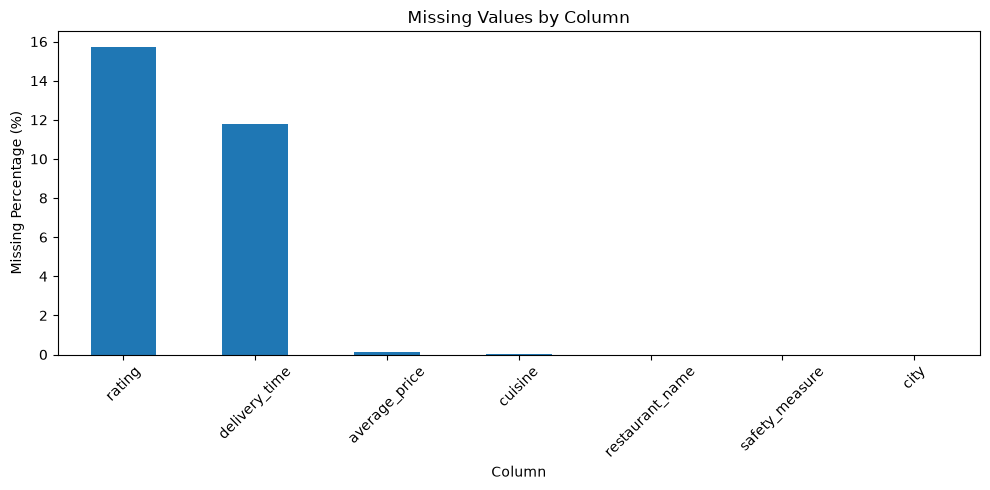

In [13]:
plt.figure(figsize=(10, 5))

missing["Missing_Percentage"].plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
# ==========================================
# 7. DUPLICATE ANALYSIS
# ==========================================

duplicate_count = cleaned.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

print(
    "Duplicate percentage:",
    round(duplicate_count / len(cleaned) * 100, 2),
    "%"
)

Exact duplicate rows: 147
Duplicate percentage: 0.33 %


In [15]:
cleaned.describe()

,rating,average_price,delivery_time
count,37826.000000,44833.000000,39592.000000
mean,3.922495,172.472375,33.184103
std,0.346783,88.221089,9.921738
min,2.400000,10.000000,6.000000
25%,3.700000,100.000000,26.000000
50%,4.000000,150.000000,32.000000
75%,4.200000,200.000000,39.000000
max,4.900000,900.000000,190.000000


In [16]:
numeric_columns = [
    "rating",
    "average_price",
    "delivery_time"
]

cleaned[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
rating,37826.0,3.922495,0.346783,2.4,3.7,4.0,4.2,4.9
average_price,44833.0,172.472375,88.221089,10.0,100.0,150.0,200.0,900.0
delivery_time,39592.0,33.184103,9.921738,6.0,26.0,32.0,39.0,190.0


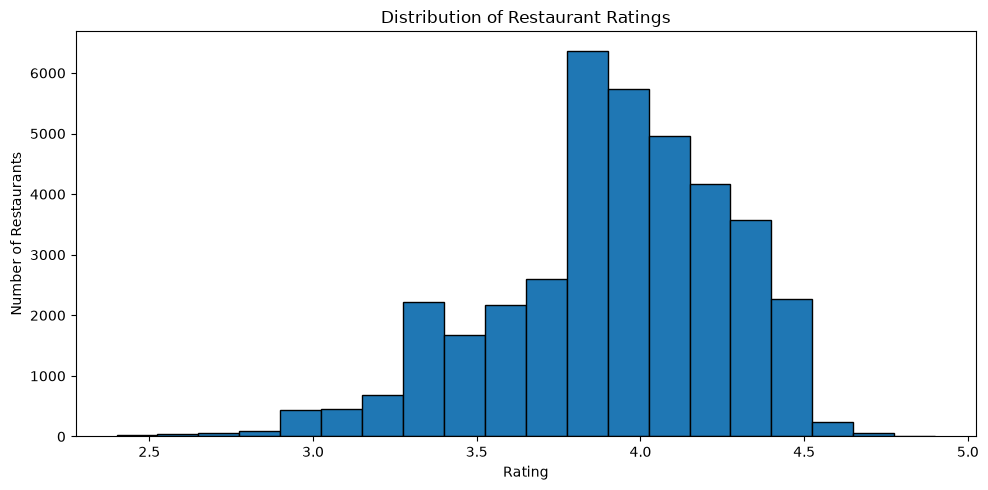

In [17]:
# ==========================================
# 10. RATING DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))

cleaned["rating"].dropna().plot(
    kind="hist",
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.show()

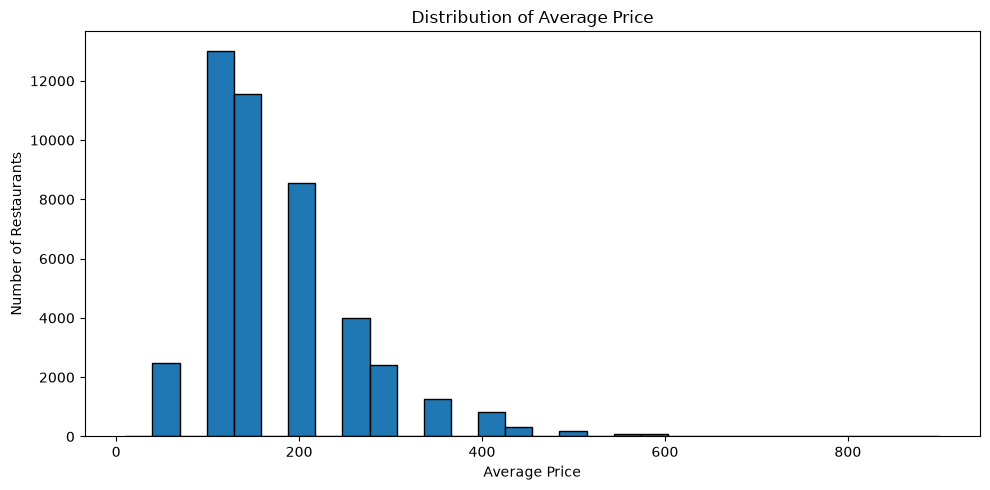

In [18]:
# ==========================================
# 11. PRICE DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))

cleaned["average_price"].dropna().plot(
    kind="hist",
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Average Price")
plt.xlabel("Average Price")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.show()

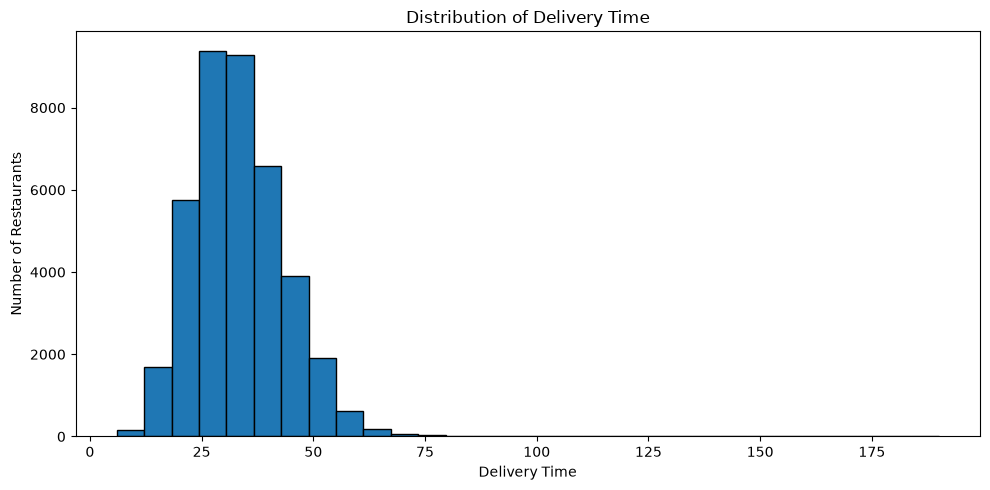

In [19]:
# ==========================================
# 12. DELIVERY TIME DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))

cleaned["delivery_time"].dropna().plot(
    kind="hist",
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.show()

In [20]:
# ==========================================
# 13. CITY ANALYSIS
# ==========================================

city_summary = cleaned.groupby("city").agg(
    restaurant_count=("restaurant_name", "count"),
    avg_rating=("rating", "mean"),
    avg_price=("average_price", "mean"),
    avg_delivery_time=("delivery_time", "mean")
).reset_index()

city_summary.head()

,city,restaurant_count,avg_rating,avg_price,avg_delivery_time
0,Agra\r,600,3.863619,169.750000,35.555000
1,Ahmedabad\r,600,3.993311,175.000000,31.450000
2,Ajmer\r,416,3.868932,157.884615,27.397590
3,Alappuzha\r,54,4.000000,158.148148,34.833333
4,Aligarh\r,324,3.885398,165.851393,26.371429


In [21]:
# ==========================================
# 14. TOP CITIES BY RESTAURANT COUNT
# ==========================================

top_cities = (
    city_summary
    .sort_values("restaurant_count", ascending=False)
    .head(15)
)

top_cities

,city,restaurant_count,avg_rating,avg_price,avg_delivery_time
51,Kolkata\r,1296,3.977345,190.115830,44.745370
48,Kanpur\r,1185,3.864813,167.088608,35.641214
65,NCR\r,1128,3.995176,201.042611,38.540780
54,Ludhiana\r,1005,3.873747,204.169154,31.632563
53,Lucknow\r,996,3.897959,174.096386,33.935678
36,Hyderabad\r,900,4.042778,192.666667,41.224444
17,Chandigarh\r,840,3.946455,182.142857,34.823810
37,Indore\r,828,3.905276,165.942029,34.844015
18,Chennai\r,828,4.012281,186.111111,42.246377
40,Jalandhar\r,818,3.898110,187.041565,28.974895


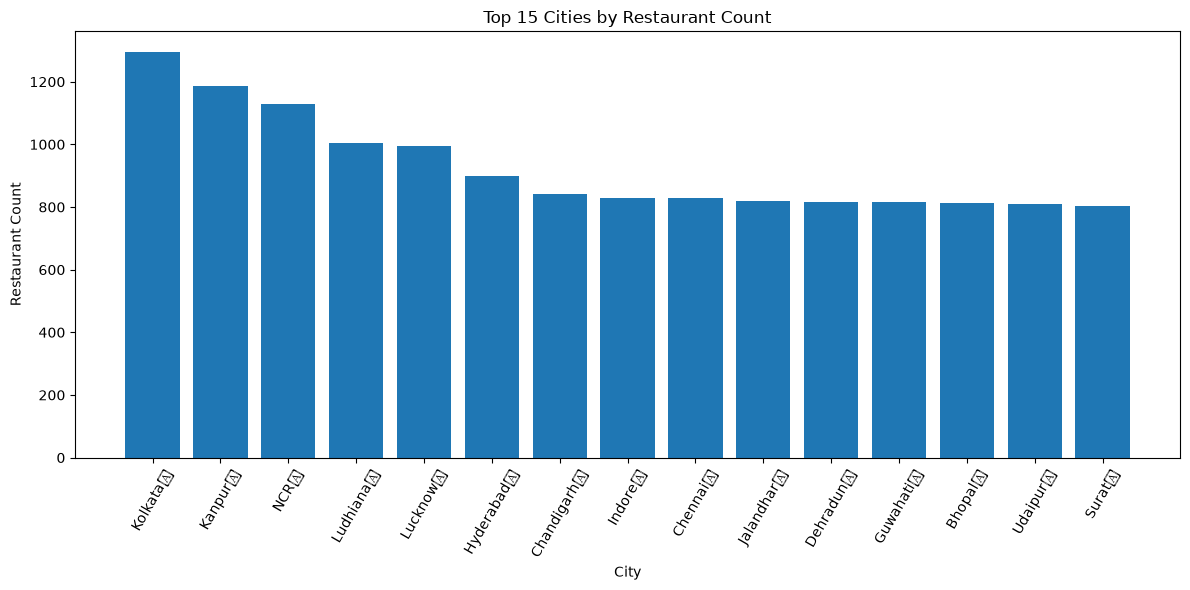

In [22]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_cities["city"],
    top_cities["restaurant_count"]
)

plt.title("Top 15 Cities by Restaurant Count")
plt.xlabel("City")
plt.ylabel("Restaurant Count")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [23]:
# ==========================================
# 15. CITY RATING ANALYSIS
# ==========================================

city_rating = (
    city_summary
    .dropna(subset=["avg_rating"])
    .sort_values("avg_rating", ascending=False)
)

city_rating.head(15)

,city,restaurant_count,avg_rating,avg_price,avg_delivery_time
24,Delhi NCR\r,313,4.092652,207.667732,41.540541
47,Junagadh\r,153,4.091667,121.721854,25.313725
74,Pune\r,768,4.075098,174.283854,36.164276
62,Mumbai\r,792,4.053992,202.272727,37.818182
10,Bangalore\r,534,4.047655,181.367041,40.700205
36,Hyderabad\r,900,4.042778,192.666667,41.224444
18,Chennai\r,828,4.012281,186.111111,42.246377
3,Alappuzha\r,54,4.000000,158.148148,34.833333
65,NCR\r,1128,3.995176,201.042611,38.540780
1,Ahmedabad\r,600,3.993311,175.000000,31.450000


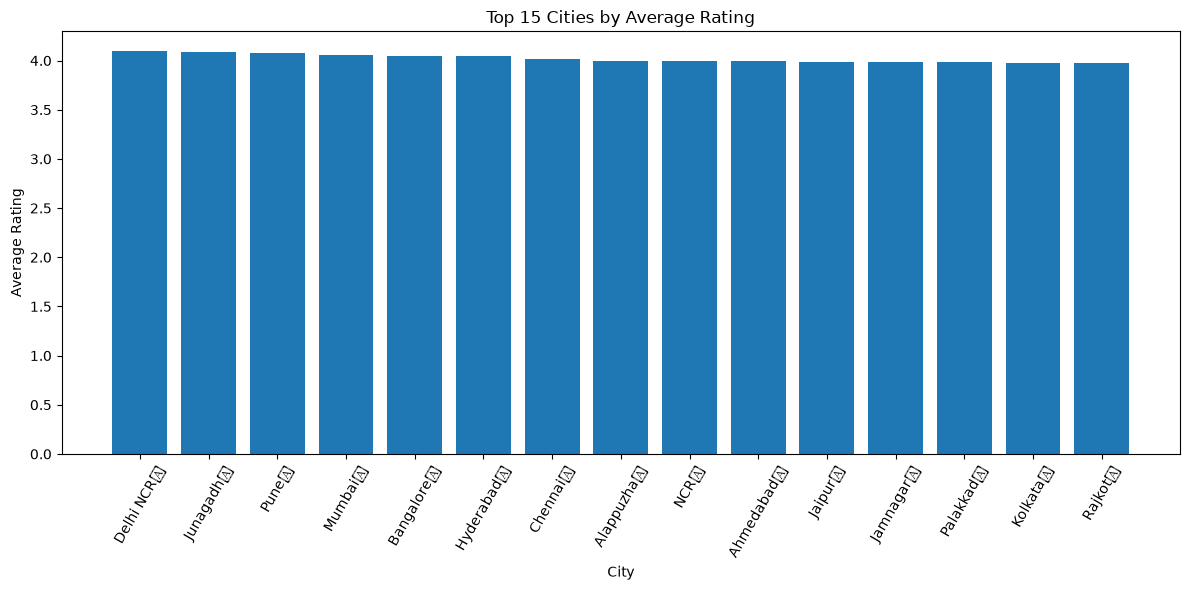

In [24]:
plt.figure(figsize=(12, 6))

plt.bar(
    city_rating.head(15)["city"],
    city_rating.head(15)["avg_rating"]
)

plt.title("Top 15 Cities by Average Rating")
plt.xlabel("City")
plt.ylabel("Average Rating")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [25]:
# ==========================================
# 16. CITY DELIVERY ANALYSIS
# ==========================================

city_delivery = (
    city_summary
    .dropna(subset=["avg_delivery_time"])
    .sort_values("avg_delivery_time")
)

city_delivery.head(15)

,city,restaurant_count,avg_rating,avg_price,avg_delivery_time
13,Bhavnagar\r,235,3.958706,128.000000,20.411765
33,Guntur\r,359,3.893226,179.469274,22.468750
58,Manipal\r,167,3.907092,162.574850,22.657143
43,Jamnagar\r,212,3.986170,132.971698,23.892857
84,Solapur\r,370,3.873883,136.162162,24.093284
95,Vijayawada\r,736,3.886979,209.972789,24.318253
81,Sangli\r,266,3.923158,124.624060,24.597561
96,Visakhapatnam\r,206,3.845294,179.126214,24.631148
47,Junagadh\r,153,4.091667,121.721854,25.313725
45,Jhansi\r,414,3.813725,146.908213,25.342949


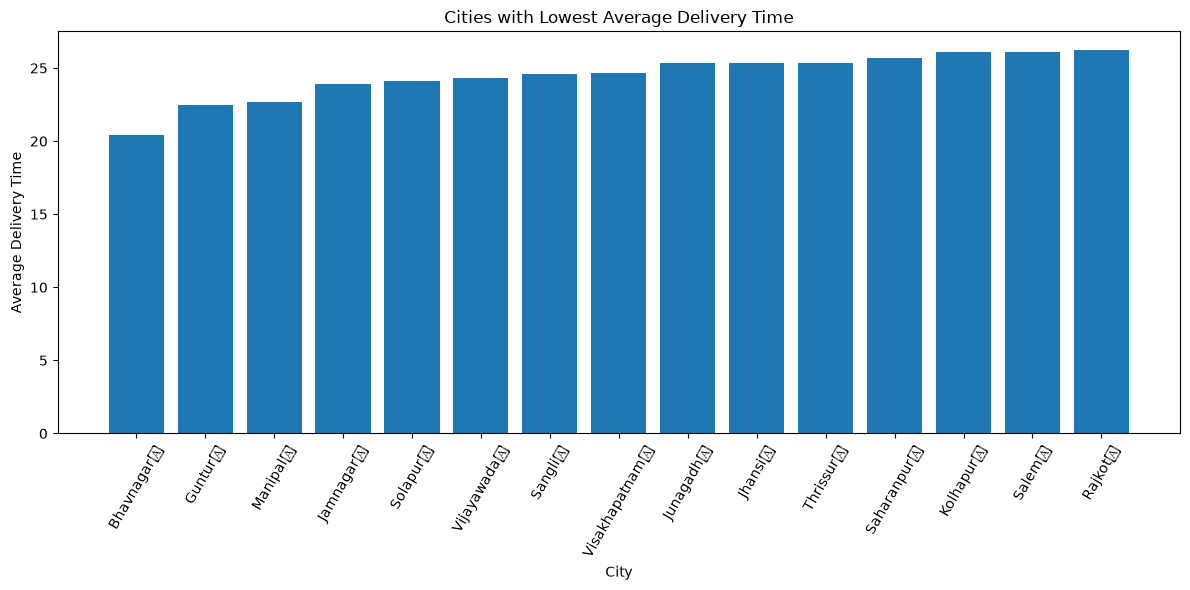

In [26]:
plt.figure(figsize=(12, 6))

plt.bar(
    city_delivery.head(15)["city"],
    city_delivery.head(15)["avg_delivery_time"]
)

plt.title("Cities with Lowest Average Delivery Time")
plt.xlabel("City")
plt.ylabel("Average Delivery Time")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [27]:
# ==========================================
# 17. CITY PRICE ANALYSIS
# ==========================================

city_price = (
    city_summary
    .dropna(subset=["avg_price"])
    .sort_values("avg_price", ascending=False)
)

city_price.head(15)

,city,restaurant_count,avg_rating,avg_price,avg_delivery_time
82,Shimla\r,46,3.896774,334.782609,46.233333
63,Mussoorie\r,7,3.800000,300.000000,NaN
30,Goa\r,455,3.921752,261.504425,31.013624
56,Manali\r,39,3.847826,230.769231,31.157895
67,Nainital\r,30,3.861538,210.000000,36.000000
95,Vijayawada\r,736,3.886979,209.972789,24.318253
24,Delhi NCR\r,313,4.092652,207.667732,41.540541
54,Ludhiana\r,1005,3.873747,204.169154,31.632563
62,Mumbai\r,792,4.053992,202.272727,37.818182
65,NCR\r,1128,3.995176,201.042611,38.540780


In [30]:
# ==========================================
# 18. SQL FINAL KPI ANALYSIS
# ==========================================

final_kpi.sort_values("overall_rank").head(20)

,city,total_restaurants,rated_restaurants,restaurants_with_delivery_data,city_avg_rating,city_avg_price,city_avg_delivery,excellent_delivery_pct,max_safety_pct,city_performance_score,rating_rank,delivery_rank,overall_rank
0,Delhi NCR\r,313,313,259,4.09,207.67,41.0,16.99,53.67,89.11,1,90,1
1,Junagadh\r,153,120,51,4.09,121.72,25.0,82.35,10.46,89.10,1,10,2
2,Pune\r,768,763,767,4.08,174.28,36.0,29.47,72.14,88.90,3,80,3
3,Mumbai\r,792,789,792,4.05,202.27,37.0,29.42,61.87,88.65,4,84,4
4,Bangalore\r,534,533,487,4.05,181.37,40.0,19.10,80.34,88.57,4,89,5
5,Hyderabad\r,900,900,900,4.04,192.67,41.0,16.56,68.56,88.51,6,90,6
6,Chennai\r,828,798,828,4.01,186.11,42.0,9.90,79.23,88.15,7,92,7
7,Alappuzha\r,54,42,36,4.00,158.15,34.0,33.33,3.70,88.00,8,65,8
8,NCR\r,1128,1078,1128,4.00,201.04,38.0,21.37,84.22,87.94,8,86,9
9,Ahmedabad\r,600,598,600,3.99,175.00,31.0,50.17,74.00,87.92,10,40,10


In [31]:
# ==========================================
# 19. CITY PERFORMANCE SCORE
# ==========================================

performance_by_city = (
    final_kpi
    .sort_values("city_performance_score", ascending=False)
)

performance_by_city[
    [
        "city",
        "city_performance_score",
        "city_avg_rating",
        "city_avg_delivery",
        "city_avg_price",
        "overall_rank"
    ]
].head(20)

,city,city_performance_score,city_avg_rating,city_avg_delivery,city_avg_price,overall_rank
0,Delhi NCR\r,89.11,4.09,41.0,207.67,1
1,Junagadh\r,89.10,4.09,25.0,121.72,2
2,Pune\r,88.90,4.08,36.0,174.28,3
3,Mumbai\r,88.65,4.05,37.0,202.27,4
4,Bangalore\r,88.57,4.05,40.0,181.37,5
5,Hyderabad\r,88.51,4.04,41.0,192.67,6
6,Chennai\r,88.15,4.01,42.0,186.11,7
7,Alappuzha\r,88.00,4.00,34.0,158.15,8
8,NCR\r,87.94,4.00,38.0,201.04,9
9,Ahmedabad\r,87.92,3.99,31.0,175.00,10


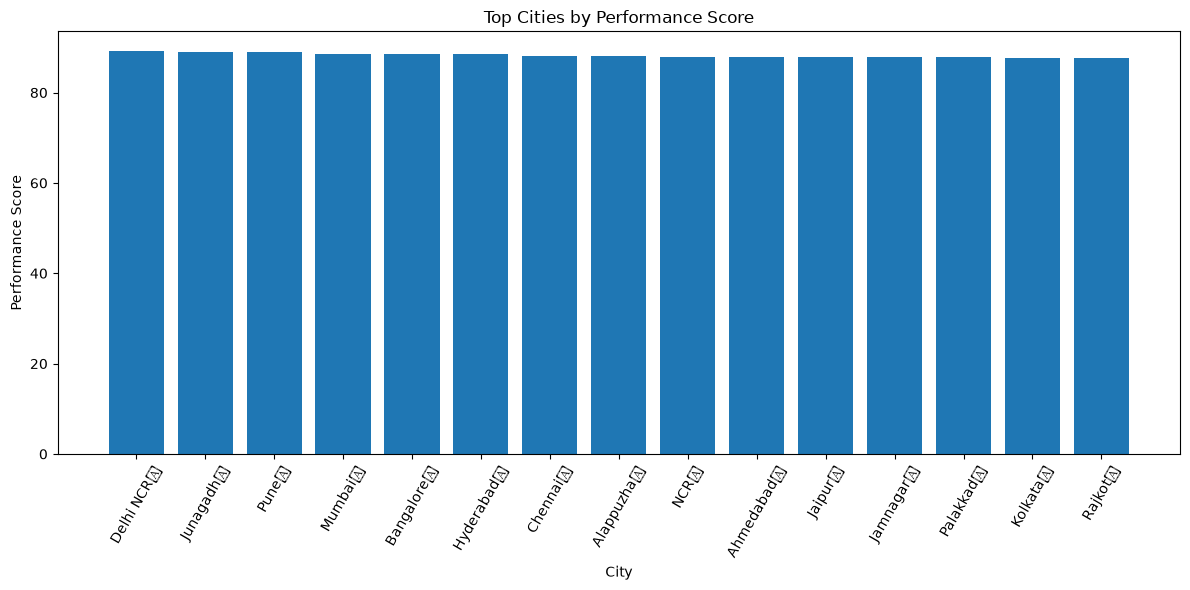

In [32]:
plt.figure(figsize=(12, 6))

top_performing_cities = performance_by_city.head(15)

plt.bar(
    top_performing_cities["city"],
    top_performing_cities["city_performance_score"]
)

plt.title("Top Cities by Performance Score")
plt.xlabel("City")
plt.ylabel("Performance Score")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [33]:
# ==========================================
# 22. MOST COMMON CUISINES
# ==========================================

top_cuisines = (
    cuisine_analysis
    .sort_values("restaurant_count", ascending=False)
    .head(15)
)

top_cuisines

,cuisine,restaurant_count,rated_restaurants,avg_rating,avg_price,avg_delivery_time
119,North Indian,18176,15686,3.90,177.48,34.0
110,Fast Food,15883,13695,3.90,171.76,34.0
51,Chinese,15240,13233,3.89,178.72,34.0
106,Beverages,12966,11562,3.95,177.91,33.0
92,Desserts,9197,8489,4.00,179.63,32.0
72,Street Food,7728,6491,3.92,165.89,32.0
86,Biryani,7465,6477,3.88,180.01,33.0
42,Pizza,6697,5626,3.86,175.68,34.0
113,South Indian,5871,5180,3.95,167.28,32.0
33,Sandwich,5092,4297,3.90,170.84,33.0


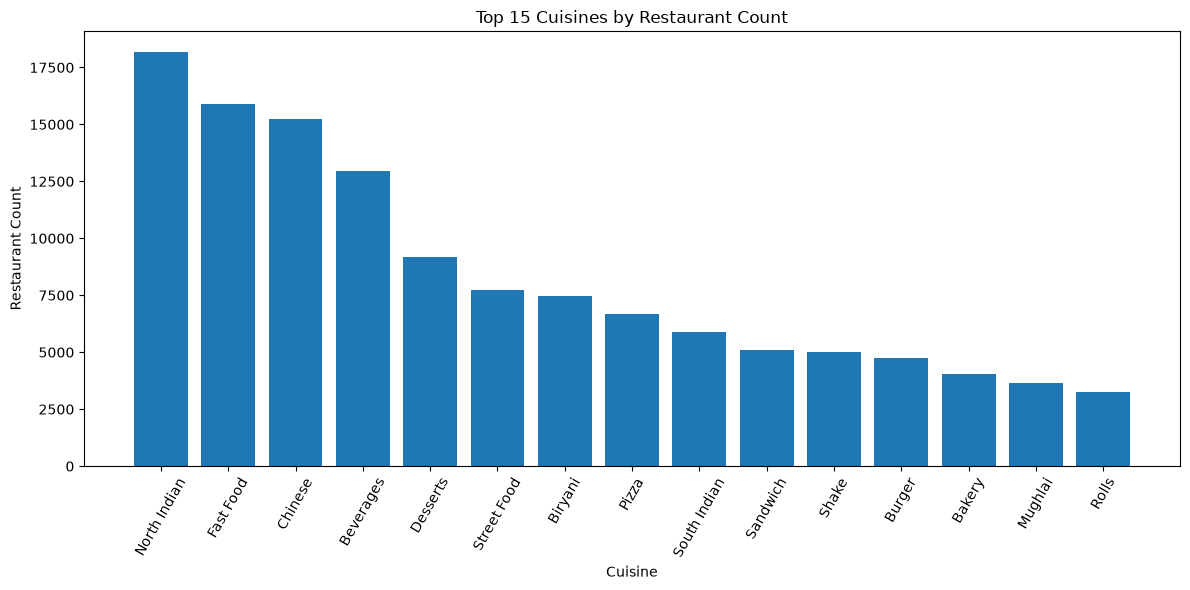

In [34]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_cuisines["cuisine"],
    top_cuisines["restaurant_count"]
)

plt.title("Top 15 Cuisines by Restaurant Count")
plt.xlabel("Cuisine")
plt.ylabel("Restaurant Count")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [35]:
# ==========================================
# 23. CUISINE RATING ANALYSIS
# ==========================================

cuisine_rating = (
    cuisine_analysis
    .sort_values("avg_rating", ascending=False)
)

cuisine_rating.head(15)

,cuisine,restaurant_count,rated_restaurants,avg_rating,avg_price,avg_delivery_time
17,Moroccan,1,1,4.50,150.00,35.0
59,German,2,2,4.40,200.00,34.0
66,Manipuri,1,1,4.30,200.00,54.0
19,Egyptian,1,1,4.30,400.00,45.0
69,Russian,2,2,4.30,200.00,32.0
118,Greek,7,7,4.27,192.86,35.0
87,Paan,91,74,4.25,160.99,27.0
35,Parsi,7,7,4.21,192.86,43.0
58,Raw Meats,2,2,4.20,150.00,34.0
27,Cantonese,11,10,4.18,245.45,44.0


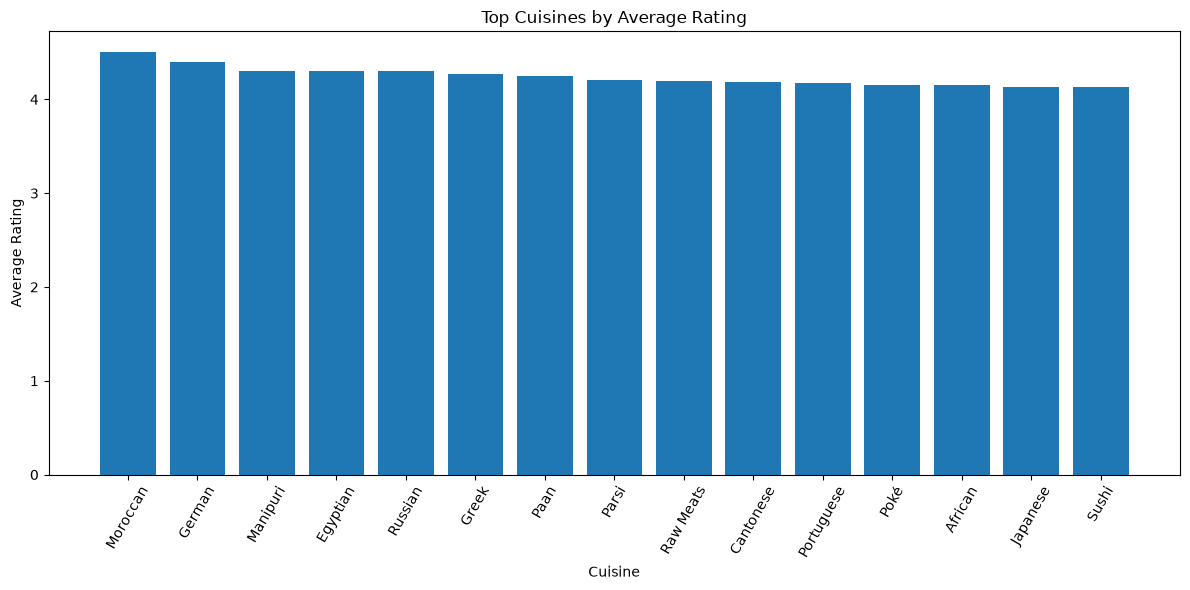

In [36]:
plt.figure(figsize=(12, 6))

top_rating_cuisines = cuisine_rating.head(15)

plt.bar(
    top_rating_cuisines["cuisine"],
    top_rating_cuisines["avg_rating"]
)

plt.title("Top Cuisines by Average Rating")
plt.xlabel("Cuisine")
plt.ylabel("Average Rating")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [37]:
# ==========================================
# 24. CUISINE PRICE ANALYSIS
# ==========================================

cuisine_price = (
    cuisine_analysis
    .sort_values("avg_price", ascending=False)
)

cuisine_price.head(15)

,cuisine,restaurant_count,rated_restaurants,avg_rating,avg_price,avg_delivery_time
19,Egyptian,1,1,4.30,400.00,45.0
97,Spanish,3,2,4.00,316.67,30.0
115,Goan,142,96,3.93,275.71,32.0
88,Bar Food,108,74,4.01,247.14,37.0
27,Cantonese,11,10,4.18,245.45,44.0
85,European,46,42,4.09,244.44,39.0
112,Belgian,4,3,3.90,237.50,28.0
89,Steak,24,24,4.03,233.33,44.0
91,Cuisine Varies,5,5,3.86,230.00,33.0
49,Mediterranean,41,35,4.10,220.51,36.0


In [38]:
# ==========================================
# 25. CUISINE DELIVERY ANALYSIS
# ==========================================

cuisine_delivery = (
    cuisine_analysis
    .dropna(subset=["avg_delivery_time"])
    .sort_values("avg_delivery_time")
)

cuisine_delivery.head(15)

,cuisine,restaurant_count,rated_restaurants,avg_rating,avg_price,avg_delivery_time
117,Drinks Only,7,6,4.10,135.71,20.0
100,Frozen Yogurt,12,12,4.03,183.33,22.0
87,Paan,91,74,4.25,160.99,27.0
112,Belgian,4,3,3.90,237.50,28.0
105,Mithai,1540,1412,4.09,166.42,28.0
5,Ice Cream,2796,2573,4.09,170.10,29.0
75,French,14,12,3.93,210.71,30.0
97,Spanish,3,2,4.00,316.67,30.0
6,Gujarati,405,363,3.96,151.80,30.0
70,Sri Lankan,2,2,3.80,100.00,30.0


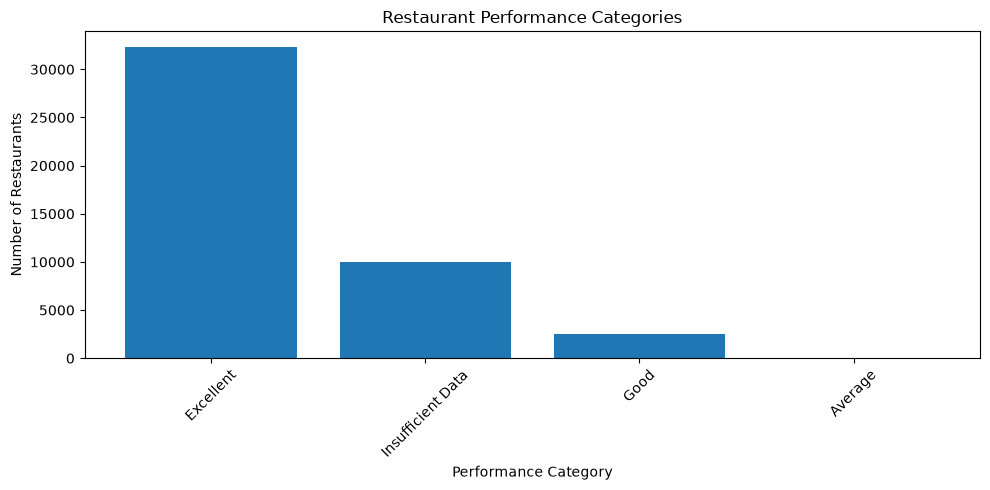

In [40]:
# ==========================================
# 27. PERFORMANCE CATEGORY DISTRIBUTION
# ==========================================

category_counts = (
    performance["performance_category"]
    .value_counts()
)

plt.figure(figsize=(10, 5))

plt.bar(
    category_counts.index,
    category_counts.values
)

plt.title("Restaurant Performance Categories")
plt.xlabel("Performance Category")
plt.ylabel("Number of Restaurants")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
# ==========================================
# 28. TOP RESTAURANTS BY PERFORMANCE
# ==========================================

top_restaurants = (
    performance
    .sort_values("performance_score", ascending=False)
    .head(20)
)

top_restaurants[
    [
        "restaurant_name",
        "city",
        "rating",
        "delivery_time",
        "average_price",
        "performance_score",
        "performance_category"
    ]
]

,restaurant_name,city,rating,delivery_time,average_price,performance_score,performance_category
19614,Rasoi Ghar Se,Palakkad\r,4.9,32.0,100.0,98.8,Excellent
26692,Hangyo Ice Cream,Manipal\r,4.9,8.0,100.0,98.8,Excellent
8944,Rambhai Special Butter Patties,Firozabad\r,4.9,29.0,100.0,98.8,Excellent
39118,Cake Waves,Trichy\r,4.9,24.0,150.0,98.8,Excellent
26058,Natural Ice Cream,Manipal\r,4.8,11.0,200.0,97.6,Excellent
38222,Peni Ice Cream,Thrissur\r,4.8,14.0,300.0,97.6,Excellent
5661,Sree Ramtilkut Bhandar (Since 1911),Gaya\r,4.8,24.0,200.0,97.6,Excellent
13112,Ibaco,Belgaum\r,4.8,21.0,200.0,97.6,Excellent
641,Herbi Vore,Aligarh\r,4.8,36.0,200.0,97.6,Excellent
40126,Oasis Vegan Treats,Vadodara\r,4.8,43.0,250.0,97.6,Excellent


In [42]:
# ==========================================
# 29. RATING VS PRICE
# ==========================================

rating_price = cleaned[
    ["rating", "average_price"]
].dropna()

correlation_price = rating_price["rating"].corr(
    rating_price["average_price"]
)

print("Pearson correlation between rating and price:",
      round(correlation_price, 4))

Pearson correlation between rating and price: -0.0047


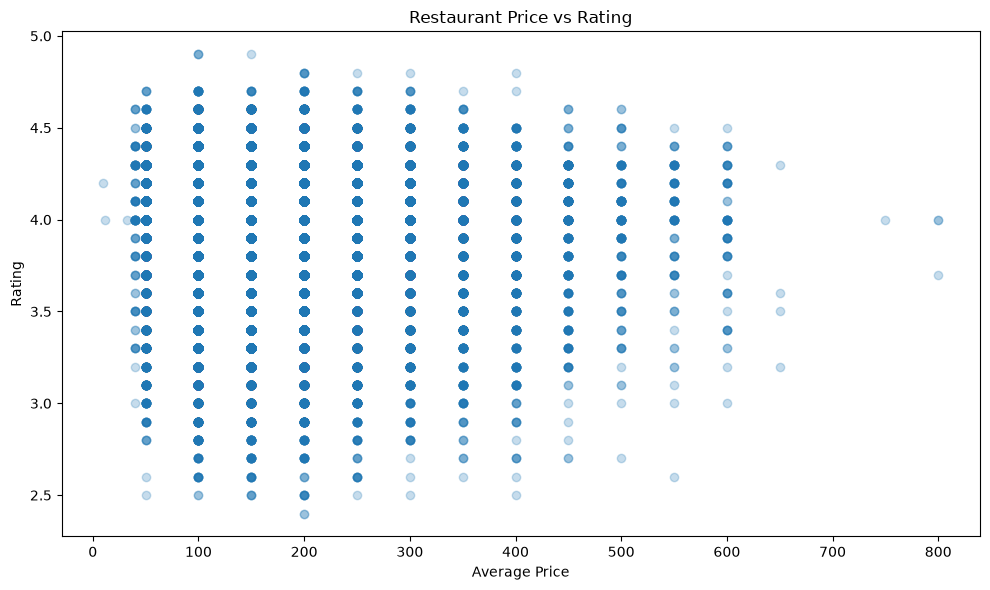

In [43]:
plt.figure(figsize=(10, 6))

plt.scatter(
    rating_price["average_price"],
    rating_price["rating"],
    alpha=0.25
)

plt.title("Restaurant Price vs Rating")
plt.xlabel("Average Price")
plt.ylabel("Rating")

plt.tight_layout()
plt.show()

In [44]:
# ==========================================
# 30. RATING VS DELIVERY TIME
# ==========================================

rating_delivery = cleaned[
    ["rating", "delivery_time"]
].dropna()

correlation_delivery = rating_delivery["rating"].corr(
    rating_delivery["delivery_time"]
)

print(
    "Pearson correlation between rating and delivery time:",
    round(correlation_delivery, 4)
)

Pearson correlation between rating and delivery time: -0.1017


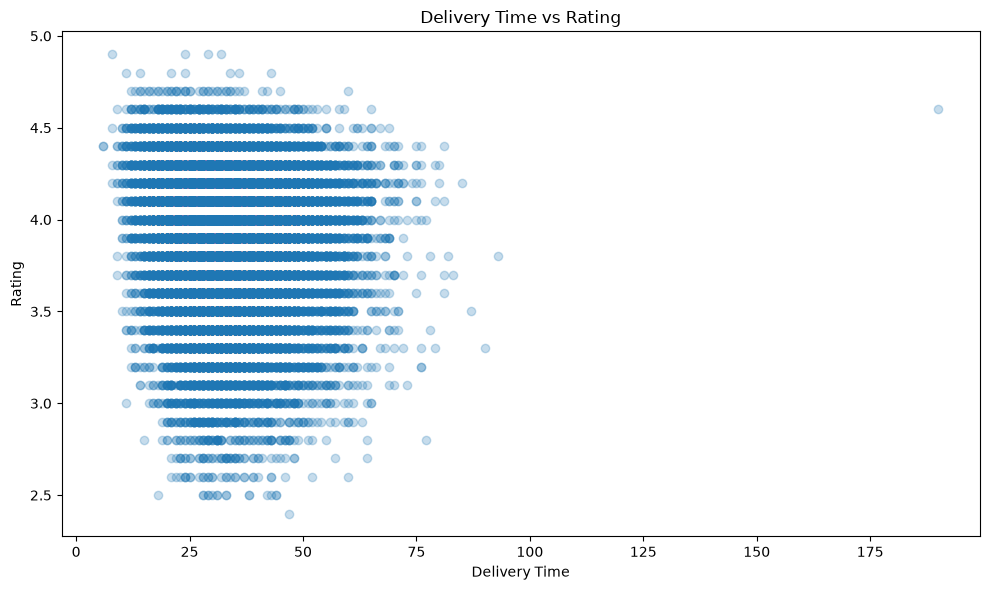

In [45]:
plt.figure(figsize=(10, 6))

plt.scatter(
    rating_delivery["delivery_time"],
    rating_delivery["rating"],
    alpha=0.25
)

plt.title("Delivery Time vs Rating")
plt.xlabel("Delivery Time")
plt.ylabel("Rating")

plt.tight_layout()
plt.show()

In [46]:
# ==========================================
# 31. RATING VS PERFORMANCE SCORE
# ==========================================

performance_corr = performance[
    ["rating", "performance_score"]
].dropna()

correlation_performance = performance_corr["rating"].corr(
    performance_corr["performance_score"]
)

print(
    "Correlation between rating and performance score:",
    round(correlation_performance, 4)
)

Correlation between rating and performance score: 0.9987


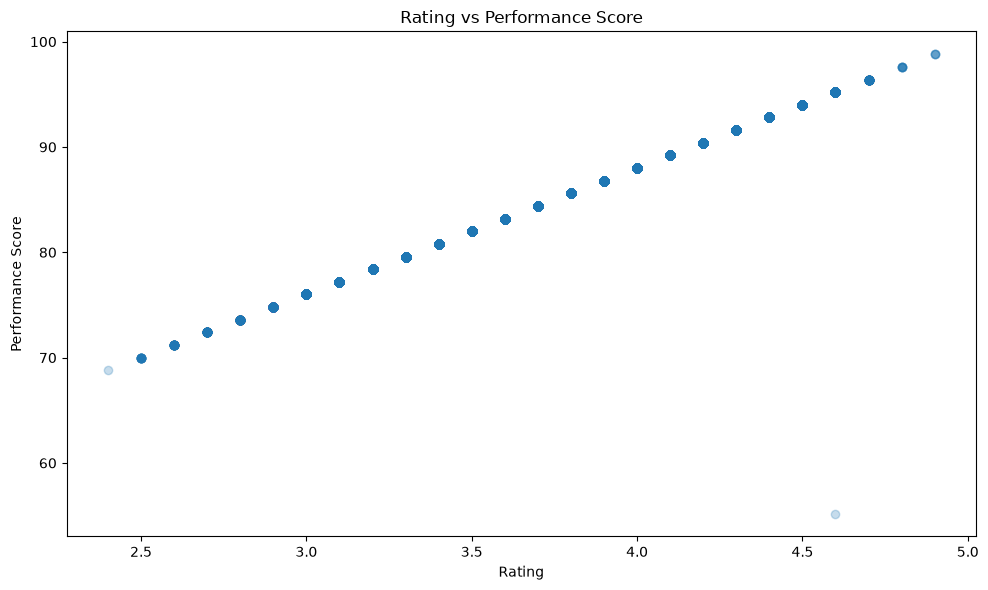

In [47]:
plt.figure(figsize=(10, 6))

plt.scatter(
    performance_corr["rating"],
    performance_corr["performance_score"],
    alpha=0.25
)

plt.title("Rating vs Performance Score")
plt.xlabel("Rating")
plt.ylabel("Performance Score")

plt.tight_layout()
plt.show()

In [48]:
# ==========================================
# 32. PRICE VS DELIVERY TIME
# ==========================================

price_delivery = cleaned[
    ["average_price", "delivery_time"]
].dropna()

correlation_price_delivery = price_delivery[
    "average_price"
].corr(
    price_delivery["delivery_time"]
)

print(
    "Correlation between price and delivery time:",
    round(correlation_price_delivery, 4)
)

Correlation between price and delivery time: 0.0556


In [49]:
# ==========================================
# 33. PEARSON + SPEARMAN CORRELATION
# ==========================================

def correlation_test(df, x, y):
    
    data = df[[x, y]].dropna()
    
    pearson = pearsonr(data[x], data[y])
    spearman = spearmanr(data[x], data[y])
    
    return {
        "Variable 1": x,
        "Variable 2": y,
        "Pearson Correlation": pearson.statistic,
        "Pearson P-Value": pearson.pvalue,
        "Spearman Correlation": spearman.statistic,
        "Spearman P-Value": spearman.pvalue
    }


correlation_results = []

pairs = [
    ("rating", "average_price"),
    ("rating", "delivery_time")
]

for x, y in pairs:
    correlation_results.append(
        correlation_test(cleaned, x, y)
    )

correlation_df = pd.DataFrame(correlation_results)

correlation_df

,Variable 1,Variable 2,Pearson Correlation,Pearson P-Value,Spearman Correlation,Spearman P-Value
0,rating,average_price,-0.004749,3.559120e-01,-0.000922,8.576940e-01
1,rating,delivery_time,-0.101705,8.144008e-81,-0.110541,3.284502e-95


In [50]:
# ==========================================
# 34. RATING BUCKETS
# ==========================================

cleaned["rating_bucket"] = pd.cut(
    cleaned["rating"],
    bins=[0, 3, 3.5, 4, 4.5, 5],
    labels=[
        "Below 3",
        "3.0–3.5",
        "3.5–4.0",
        "4.0–4.5",
        "4.5–5.0"
    ]
)

rating_bucket_summary = cleaned.groupby(
    "rating_bucket",
    observed=True
).agg(
    restaurant_count=("restaurant_name", "count"),
    avg_price=("average_price", "mean"),
    avg_delivery=("delivery_time", "mean")
).reset_index()

rating_bucket_summary

,rating_bucket,restaurant_count,avg_price,avg_delivery
0,Below 3,634,179.447077,34.627787
1,3.0–3.5,5035,171.960239,34.985567
2,3.5–4.0,16868,172.704912,34.010446
3,4.0–4.5,14976,172.994588,32.520502
4,4.5–5.0,313,165.686901,29.197842


In [51]:
# ==========================================
# 35. DELIVERY TIME BUCKETS
# ==========================================

cleaned["delivery_bucket"] = pd.cut(
    cleaned["delivery_time"],
    bins=[0, 20, 30, 40, 60, np.inf],
    labels=[
        "Under 20 min",
        "20–30 min",
        "30–40 min",
        "40–60 min",
        "60+ min"
    ]
)

delivery_bucket_summary = cleaned.groupby(
    "delivery_bucket",
    observed=True
).agg(
    restaurant_count=("restaurant_name", "count"),
    avg_rating=("rating", "mean"),
    avg_price=("average_price", "mean")
).reset_index()

delivery_bucket_summary

,delivery_bucket,restaurant_count,avg_rating,avg_price
0,Under 20 min,3223,4.041916,168.392802
1,20–30 min,13765,3.938995,172.397529
2,30–40 min,13989,3.900761,175.783865
3,40–60 min,8262,3.887480,183.041106
4,60+ min,353,3.899128,192.045455


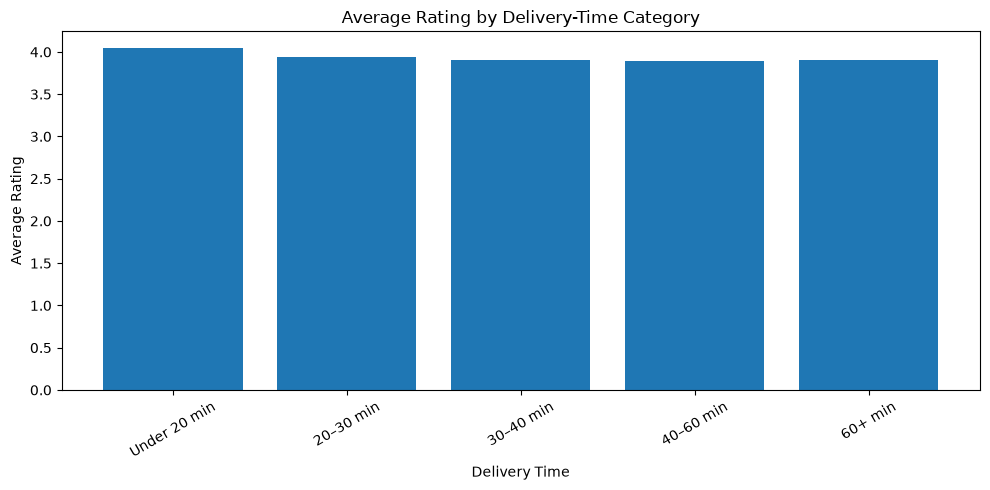

In [52]:
plt.figure(figsize=(10, 5))

plt.bar(
    delivery_bucket_summary["delivery_bucket"].astype(str),
    delivery_bucket_summary["avg_rating"]
)

plt.title("Average Rating by Delivery-Time Category")
plt.xlabel("Delivery Time")
plt.ylabel("Average Rating")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [53]:
 # ==========================================
# 37. SAFETY ANALYSIS
# ==========================================

safety_summary = cleaned.groupby(
    "safety_measure"
).agg(
    restaurant_count=("restaurant_name", "count"),
    avg_rating=("rating", "mean"),
    avg_price=("average_price", "mean"),
    avg_delivery=("delivery_time", "mean")
).reset_index()

safety_summary

,safety_measure,restaurant_count,avg_rating,avg_price,avg_delivery
0,Max Safety,25726,3.933675,172.655325,33.356250
1,WHO Protocol,19165,3.905530,172.226900,32.930246


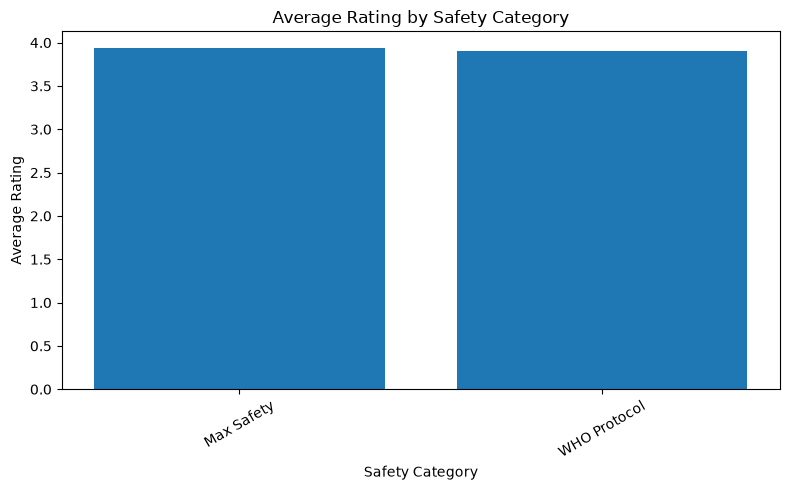

In [54]:
plt.figure(figsize=(8, 5))

plt.bar(
    safety_summary["safety_measure"],
    safety_summary["avg_rating"]
)

plt.title("Average Rating by Safety Category")
plt.xlabel("Safety Category")
plt.ylabel("Average Rating")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [55]:
cuisine_frequency = (
    restaurant_cuisine
    .groupby("cuisine")
    .agg(
        restaurant_count=("restaurant_name", "nunique"),
        avg_rating=("rating", "mean"),
        avg_price=("average_price", "mean"),
        avg_delivery=("delivery_time", "mean")
    )
    .reset_index()
    .sort_values("restaurant_count", ascending=False)
)

cuisine_frequency.head(20)

,cuisine,restaurant_count,avg_rating,avg_price,avg_delivery
84,North Indian,15790,3.895888,177.477145,34.336880
28,Chinese,13736,3.894612,178.723237,34.657456
36,Fast Food,13233,3.901490,171.762631,34.084035
15,Beverages,10572,3.948746,177.914319,33.758197
113,Street Food,7057,3.918795,165.888903,32.829159
32,Desserts,6654,4.000130,179.630210,32.513125
17,Biryani,6410,3.879744,180.005360,33.792694
92,Pizza,5539,3.855617,175.677574,34.532712
109,South Indian,5347,3.949923,167.275827,32.751605
101,Sandwich,4441,3.904422,170.841030,33.756636


In [56]:
# ==========================================
# 40. MOST EXPENSIVE CUISINES
# ==========================================

cuisine_frequency[
    cuisine_frequency["restaurant_count"] >= 20
].sort_values(
    "avg_price",
    ascending=False
).head(15)

,cuisine,restaurant_count,avg_rating,avg_price,avg_delivery
42,Goan,141,3.928125,275.714286,32.756757
12,Bar Food,108,4.010811,247.142857,37.808989
35,European,46,4.085714,244.444444,39.232558
112,Steak,23,4.029167,233.333333,44.565217
71,Mediterranean,37,4.100000,220.512821,36.842105
55,Japanese,104,4.134862,216.101695,42.628319
30,Continental,1400,4.004272,210.856574,36.739069
86,Oriental,203,4.020096,210.822511,37.340909
6,Asian,503,4.038023,209.683099,39.908088
24,Cake,50,3.940426,209.000000,37.686275


In [57]:
# ==========================================
# 41. BEST-RATED CUISINES
# ==========================================

cuisine_frequency[
    cuisine_frequency["restaurant_count"] >= 20
].sort_values(
    "avg_rating",
    ascending=False
).head(15)

,cuisine,restaurant_count,avg_rating,avg_price,avg_delivery
87,Paan,79,4.248649,160.989011,27.475610
55,Japanese,104,4.134862,216.101695,42.628319
114,Sushi,91,4.134343,203.333333,42.392157
88,Pancake,86,4.114474,187.125749,34.125000
71,Mediterranean,37,4.100000,220.512821,36.842105
73,Middle Eastern,31,4.090625,202.941176,39.848485
75,Mithai,1337,4.089235,166.421601,28.913468
50,Ice Cream,1677,4.087330,170.096567,29.000000
35,European,46,4.085714,244.444444,39.232558
49,Hyderabadi,119,4.076498,188.565022,36.757143


In [58]:
# ==========================================
# 42. SQL VS PYTHON CITY VALIDATION
# ==========================================

python_city = cleaned.groupby("city").agg(
    total_restaurants=("restaurant_name", "count"),
    city_avg_rating=("rating", "mean"),
    city_avg_price=("average_price", "mean"),
    city_avg_delivery=("delivery_time", "mean")
).reset_index()

python_city.head()

,city,total_restaurants,city_avg_rating,city_avg_price,city_avg_delivery
0,Agra\r,600,3.863619,169.750000,35.555000
1,Ahmedabad\r,600,3.993311,175.000000,31.450000
2,Ajmer\r,416,3.868932,157.884615,27.397590
3,Alappuzha\r,54,4.000000,158.148148,34.833333
4,Aligarh\r,324,3.885398,165.851393,26.371429


In [59]:
sql_python_comparison = final_kpi.merge(
    python_city,
    on="city",
    how="left",
    suffixes=("_sql", "_python")
)

sql_python_comparison.head()

,city,total_restaurants_sql,rated_restaurants,restaurants_with_delivery_data,city_avg_rating_sql,city_avg_price_sql,city_avg_delivery_sql,excellent_delivery_pct,max_safety_pct,city_performance_score,rating_rank,delivery_rank,overall_rank,total_restaurants_python,city_avg_rating_python,city_avg_price_python,city_avg_delivery_python
0,Delhi NCR\r,313,313,259,4.09,207.67,41.0,16.99,53.67,89.11,1,90,1,313,4.092652,207.667732,41.540541
1,Junagadh\r,153,120,51,4.09,121.72,25.0,82.35,10.46,89.10,1,10,2,153,4.091667,121.721854,25.313725
2,Pune\r,768,763,767,4.08,174.28,36.0,29.47,72.14,88.90,3,80,3,768,4.075098,174.283854,36.164276
3,Mumbai\r,792,789,792,4.05,202.27,37.0,29.42,61.87,88.65,4,84,4,792,4.053992,202.272727,37.818182
4,Bangalore\r,534,533,487,4.05,181.37,40.0,19.10,80.34,88.57,4,89,5,534,4.047655,181.367041,40.700205


In [60]:
# ==========================================
# 43. RATING VALIDATION
# ==========================================

sql_python_comparison["rating_difference"] = (
    sql_python_comparison["city_avg_rating_sql"]
    -
    sql_python_comparison["city_avg_rating_python"]
)

sql_python_comparison[
    [
        "city",
        "city_avg_rating_sql",
        "city_avg_rating_python",
        "rating_difference"
    ]
].sort_values(
    "rating_difference",
    key=abs,
    ascending=False
).head(20)


,city,city_avg_rating_sql,city_avg_rating_python,rating_difference
2,Pune\r,4.08,4.075098,0.004902
64,Jodhpur\r,3.89,3.885133,0.004867
8,NCR\r,4.00,3.995176,0.004824
84,Jalgaon\r,3.85,3.854822,-0.004822
78,Kanpur\r,3.86,3.864813,-0.004813
65,Rishikesh\r,3.89,3.885246,0.004754
25,Warangal\r,3.93,3.934728,-0.004728
44,Indore\r,3.91,3.905276,0.004724
91,Visakhapatnam\r,3.85,3.845294,0.004706
85,Gorakhpur\r,3.85,3.854676,-0.004676


In [61]:
# ==========================================
# 44. PRICE VALIDATION
# ==========================================

sql_python_comparison["price_difference"] = (
    sql_python_comparison["city_avg_price_sql"]
    -
    sql_python_comparison["city_avg_price_python"]
)

sql_python_comparison[
    [
        "city",
        "city_avg_price_sql",
        "city_avg_price_python",
        "price_difference"
    ]
].sort_values(
    "price_difference",
    key=abs,
    ascending=False
).head(20)

,city,city_avg_price_sql,city_avg_price_python,price_difference
51,Aurangabad\r,131.88,131.875000,0.005000
25,Warangal\r,146.75,146.754967,-0.004967
45,Udaipur\r,181.32,181.315136,0.004864
41,Manipal\r,162.57,162.574850,-0.004850
15,Ranchi\r,188.10,188.095238,0.004762
75,Ajmer\r,157.88,157.884615,-0.004615
94,Amritsar\r,172.12,172.115385,0.004615
81,Saharanpur\r,135.21,135.205479,0.004521
33,Asansol\r,155.56,155.555556,0.004444
64,Jodhpur\r,172.83,172.834437,-0.004437


In [62]:
# ==========================================
# 45. DELIVERY VALIDATION
# ==========================================

sql_python_comparison["delivery_difference"] = (
    sql_python_comparison["city_avg_delivery_sql"]
    -
    sql_python_comparison["city_avg_delivery_python"]
)

sql_python_comparison[
    [
        "city",
        "city_avg_delivery_sql",
        "city_avg_delivery_python",
        "delivery_difference"
    ]
].sort_values(
    "delivery_difference",
    key=abs,
    ascending=False
).head(20)

,city,city_avg_delivery_sql,city_avg_delivery_python,delivery_difference
50,Jalandhar\r,28.0,28.974895,-0.974895
73,Patiala\r,26.0,26.938596,-0.938596
49,Lucknow\r,33.0,33.935678,-0.935678
12,Palakkad\r,30.0,30.933962,-0.933962
19,Durgapur\r,32.0,32.914027,-0.914027
37,Guwahati\r,42.0,42.896465,-0.896465
11,Jamnagar\r,23.0,23.892857,-0.892857
23,Madurai\r,29.0,29.883249,-0.883249
59,Dhanbad\r,32.0,32.859223,-0.859223
94,Amritsar\r,28.0,28.855769,-0.855769


In [63]:
# ==========================================
# 46. PYTHON EXECUTION TIME
# ==========================================

import time

start_time = time.perf_counter()

python_city_test = cleaned.groupby("city").agg(
    total_restaurants=("restaurant_name", "count"),
    avg_rating=("rating", "mean"),
    avg_price=("average_price", "mean"),
    avg_delivery=("delivery_time", "mean")
).reset_index()

python_execution_time = time.perf_counter() - start_time

print(
    f"Python execution time: {python_execution_time:.6f} seconds"
)

Python execution time: 0.009671 seconds


In [64]:
# ==========================================
# 47. SQL ROLLING TABLE
# ==========================================

rolling.head(20)

,restaurant_name,city,rating,rolling_3_restaurant_avg
0,Garlick,Agra\r,4.6,4.60
1,Brijwasi Petha,Agra\r,4.6,4.60
2,Tiwari Bombay Style Bhel And Panipuri,Agra\r,4.6,4.60
3,Goyal Cakes & Bakes,Agra\r,4.5,4.57
4,Kings Kulfi And Icecreams,Agra\r,4.5,4.53
5,Havmor Havfunn Ice Cream,Agra\r,4.5,4.50
6,Rajendra Sweets Online,Agra\r,4.5,4.50
7,Grameen Kulfi,Agra\r,4.5,4.50
8,Pape Ka Dhabha,Agra\r,4.4,4.47
9,Freaky Burger,Agra\r,4.4,4.43


In [65]:
# ==========================================
# 48. PYTHON ROLLING AVERAGE
# ==========================================

rolling_python = (
    cleaned
    .dropna(subset=["rating"])
    .sort_values(["city", "restaurant_name"])
    .copy()
)

rolling_python["rolling_3_restaurant_avg"] = (
    rolling_python
    .groupby("city")["rating"]
    .transform(
        lambda x: x.rolling(
            window=3,
            min_periods=1
        ).mean()
    )
)

rolling_python[
    [
        "restaurant_name",
        "city",
        "rating",
        "rolling_3_restaurant_avg"
    ]
].head(20)

,restaurant_name,city,rating,rolling_3_restaurant_avg
3647,2ND Wife,Agra\r,4.2,4.200000
3553,3C's Cafe,Agra\r,4.0,4.100000
3522,3C's Shake Time,Agra\r,4.0,4.066667
1429,A & C Burger Shoppee,Agra\r,4.1,4.033333
5978,A One Fast Food,Agra\r,3.0,3.700000
1423,AK Pizza Wala,Agra\r,4.0,3.700000
1313,Aahar,Agra\r,4.2,3.733333
1471,Abhishek Dhaba,Agra\r,3.8,4.000000
3470,Achman Foods,Agra\r,4.2,4.066667
3671,Aelicious Cafe,Agra\r,3.5,3.833333


In [66]:
# ==========================================
# 49. CORRELATION MATRIX
# ==========================================

correlation_matrix = cleaned[
    [
        "rating",
        "average_price",
        "delivery_time"
    ]
].corr()

correlation_matrix

,rating,average_price,delivery_time
rating,1.000000,-0.004749,-0.101705
average_price,-0.004749,1.000000,0.055637
delivery_time,-0.101705,0.055637,1.000000


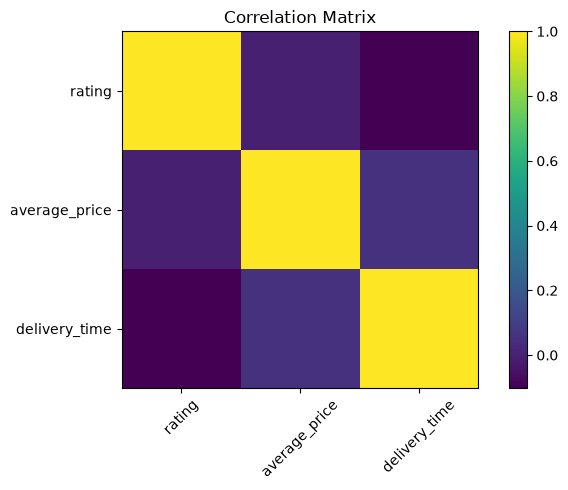

In [67]:
plt.figure(figsize=(7, 5))

plt.imshow(
    correlation_matrix,
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [68]:
# ==========================================
# 50. OVERALL PROJECT KPI
# ==========================================

overall_kpi = {
    "Total Records": len(cleaned),
    "Unique Restaurants": cleaned["restaurant_name"].nunique(),
    "Cities": cleaned["city"].nunique(),
    "Cuisines": restaurant_cuisine["cuisine"].nunique(),
    "Average Rating": cleaned["rating"].mean(),
    "Average Price": cleaned["average_price"].mean(),
    "Average Delivery Time": cleaned["delivery_time"].mean(),
    "Rated Restaurants": cleaned["rating"].notna().sum(),
    "Restaurants With Delivery Data": cleaned["delivery_time"].notna().sum()
}

overall_kpi_df = pd.DataFrame(
    overall_kpi.items(),
    columns=["Metric", "Value"]
)

overall_kpi_df

,Metric,Value
0,Total Records,44891.000000
1,Unique Restaurants,35688.000000
2,Cities,98.000000
3,Cuisines,124.000000
4,Average Rating,3.922495
5,Average Price,172.472375
6,Average Delivery Time,33.184103
7,Rated Restaurants,37826.000000
8,Restaurants With Delivery Data,39592.000000


In [69]:
# ==========================================
# 51. BUSINESS INSIGHTS
# ==========================================

highest_rated_city = (
    final_kpi
    .sort_values("city_avg_rating", ascending=False)
    .iloc[0]
)

fastest_city = (
    final_kpi
    .dropna(subset=["city_avg_delivery"])
    .sort_values("city_avg_delivery")
    .iloc[0]
)

largest_city = (
    final_kpi
    .sort_values("total_restaurants", ascending=False)
    .iloc[0]
)

highest_performance_city = (
    final_kpi
    .dropna(subset=["city_performance_score"])
    .sort_values("city_performance_score", ascending=False)
    .iloc[0]
)

print("BUSINESS INSIGHTS")
print("=" * 60)

print(
    f"City with highest average rating: "
    f"{highest_rated_city['city']}"
)

print(
    f"Fastest average delivery city: "
    f"{fastest_city['city']}"
)

print(
    f"City with most restaurants: "
    f"{largest_city['city']}"
)

print(
    f"Highest city performance score: "
    f"{highest_performance_city['city']}"
)

BUSINESS INSIGHTS
City with highest average rating: Delhi NCR
Fastest average delivery city: Bhavnagar
City with most restaurants: Kolkata
Highest city performance score: Delhi NCR


In [71]:
# ==========================================
# 52. EXPORT PYTHON ANALYSIS
# ==========================================

city_summary.to_csv(
    "Python_City_Analysis.csv",
    index=False
)

cuisine_frequency.to_csv(
    "Python_Cuisine_Analysis.csv",
    index=False
)

rating_bucket_summary.to_csv(
    "Python_Rating_Bucket_Analysis.csv",
    index=False
)

delivery_bucket_summary.to_csv(
    "Python_Delivery_Analysis.csv",
    index=False
)

correlation_df.to_csv(
    "Python_Correlation_Analysis.csv",
    index=False
)

overall_kpi_df.to_csv(
    "Python_Overall_KPI.csv",
    index=False
)

sql_python_comparison.to_csv(
    "SQL_vs_Python_Comparison.csv",
    index=False
)

print("Analysis files exported successfully.")

Analysis files exported successfully.


In [1]:
import pyodbc

print(pyodbc.drivers())

['ODBC Driver 18 for SQL Server']


In [1]:
import pymssql

conn = pymssql.connect(
    server="localhost",
    port=1433,
    user="sa",
    password="Aditya@123",
    database="ZomatoDB"
)

print("Connected successfully!")

Connected successfully!


In [2]:
import pandas as pd

df_sql = pd.read_sql(
    "SELECT TOP 10 * FROM dbo.Zomato_Cleaned",
    conn
)

df_sql

/var/folders/55/j0sg7xz91cd5qn5dd348f18r0000gn/T/ipykernel_63566/3307921958.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_sql = pd.read_sql(


,restaurant_name,rating,cuisine,average_price,delivery_time,safety_measure,city
0,Italian House,NaN,"Chinese, Burger",100.0,21,Max Safety,Amritsar\r
1,Vegelicious Amritsar,NaN,"Chinese, Pizza, Sandwich, Pasta, Burger, Momos...",100.0,36,Max Safety,Amritsar\r
2,Street 88 Cafe,3.5,"Pizza, Burger, Fast Food, Shake",100.0,27,Max Safety,Amritsar\r
3,Momo's & More,4.0,"Momos, Burger, Fast Food",100.0,35,Max Safety,Amritsar\r
4,Nutrition Treat,4.2,"North Indian, Salad, Sandwich, Burger, Beverag...",100.0,40,Max Safety,Amritsar\r
5,Happy Paneer Wala,3.8,"Fast Food, Street Food",300.0,33,Max Safety,Amritsar\r
6,The Snacks In Seconds,NaN,"North Indian, Chinese, Seafood, Biryani",300.0,20,Max Safety,Amritsar\r
7,Hotel Millennium,NaN,"North Indian, Mughlai, Chinese, Beverages, Sic...",300.0,34,Max Safety,Amritsar\r
8,Bozi Zazrak,3.7,"Pizza, Hot dogs, Sandwich, Fast Food, Wraps, S...",300.0,30,Max Safety,Amritsar\r
9,Shri Brijwasi Food,3.9,Street Food,300.0,20,Max Safety,Amritsar\r


In [3]:
query = "SELECT COUNT(*) AS total_rows FROM dbo.Zomato_Cleaned"

pd.read_sql(query, conn)

/var/folders/55/j0sg7xz91cd5qn5dd348f18r0000gn/T/ipykernel_63566/3276575930.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(query, conn)


,total_rows
0,44891


In [4]:
columns = pd.read_sql("""
SELECT 
    COLUMN_NAME,
    DATA_TYPE
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_NAME = 'Zomato_Cleaned'
ORDER BY ORDINAL_POSITION
""", conn)

columns

/var/folders/55/j0sg7xz91cd5qn5dd348f18r0000gn/T/ipykernel_63566/320766932.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  columns = pd.read_sql("""


,COLUMN_NAME,DATA_TYPE
0,restaurant_name,nvarchar
1,rating,decimal
2,cuisine,nvarchar
3,average_price,decimal
4,delivery_time,int
5,safety_measure,nvarchar
6,city,nvarchar


In [5]:
import time

def run_sql(query):
    start = time.perf_counter()
    result = pd.read_sql(query, conn)
    elapsed = time.perf_counter() - start
    return result, elapsed


def benchmark_python(func):
    start = time.perf_counter()
    result = func()
    elapsed = time.perf_counter() - start
    return result, elapsed

In [6]:
start = time.perf_counter()

df_all = pd.read_sql("""
SELECT
    restaurant_name,
    rating,
    cuisine,
    average_price,
    delivery_time,
    safety_measure,
    city
FROM dbo.Zomato_Cleaned
""", conn)

load_time = time.perf_counter() - start

print(f"Rows loaded: {len(df_all):,}")
print(f"Load time: {load_time:.4f} seconds")

/var/folders/55/j0sg7xz91cd5qn5dd348f18r0000gn/T/ipykernel_63566/2642869139.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_all = pd.read_sql("""


Rows loaded: 44,891
Load time: 0.2272 seconds


In [16]:
sql_city_query = """
SELECT
    city,
    COUNT(DISTINCT LOWER(LTRIM(RTRIM(restaurant_name)))) AS restaurant_count,
    ROUND(AVG(CAST(rating AS FLOAT)), 2) AS avg_rating,
    ROUND(AVG(CAST(average_price AS FLOAT)), 2) AS avg_price,
    ROUND(AVG(CAST(delivery_time AS FLOAT)), 2) AS avg_delivery_time
FROM dbo.Zomato_Cleaned
GROUP BY city
ORDER BY avg_rating DESC
"""

sql_city_kpi, sql_city_time = run_sql(sql_city_query)

print(f"SQL execution time: {sql_city_time:.4f} seconds")

sql_city_kpi

SQL execution time: 0.1534 seconds


/var/folders/55/j0sg7xz91cd5qn5dd348f18r0000gn/T/ipykernel_63566/388587291.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,city,restaurant_count,avg_rating,avg_price,avg_delivery_time
0,Delhi NCR\r,270,4.09,207.67,41.54
1,Junagadh\r,144,4.09,121.72,25.31
2,Pune\r,747,4.08,174.28,36.16
3,Mumbai\r,776,4.05,202.27,37.82
4,Bangalore\r,492,4.05,181.37,40.70
...,...,...,...,...,...
93,Gaya\r,233,3.82,146.07,28.30
94,Amritsar\r,619,3.82,172.12,28.86
95,Jhansi\r,402,3.81,146.91,25.34
96,Motihari\r,45,3.81,170.21,52.19


In [17]:
df_all["restaurant_name_clean"] = (
    df_all["restaurant_name"]
    .astype(str)
    .str.strip()
    .str.lower()
)

In [18]:
def python_city_kpi():
    result = (
        df_all
        .groupby("city")
        .agg(
            restaurant_count=("restaurant_name_clean", "nunique"),
            avg_rating=("rating", "mean"),
            avg_price=("average_price", "mean"),
            avg_delivery_time=("delivery_time", "mean")
        )
        .reset_index()
    )

    result["avg_rating"] = result["avg_rating"].round(2)
    result["avg_price"] = result["avg_price"].round(2)
    result["avg_delivery_time"] = result["avg_delivery_time"].round(2)

    return result.sort_values("avg_rating", ascending=False)


python_city_kpi, python_city_time = benchmark_python(python_city_kpi)

print(f"Python execution time: {python_city_time:.4f} seconds")

python_city_kpi

Python execution time: 0.0306 seconds


,city,restaurant_count,avg_rating,avg_price,avg_delivery_time
47,Junagadh\r,144,4.09,121.72,25.31
24,Delhi NCR\r,270,4.09,207.67,41.54
74,Pune\r,747,4.08,174.28,36.16
62,Mumbai\r,776,4.05,202.27,37.82
10,Bangalore\r,492,4.05,181.37,40.70
...,...,...,...,...,...
7,Amritsar\r,619,3.82,172.12,28.86
29,Gaya\r,233,3.82,146.07,28.30
45,Jhansi\r,402,3.81,146.91,25.34
61,Motihari\r,45,3.81,170.21,52.19


In [21]:
sql_check = sql_city_kpi.sort_values("city").reset_index(drop=True)
python_check = python_city_kpi.sort_values("city").reset_index(drop=True)

print(
    "Results match:",
    sql_check.round(2).equals(python_check.round(2))
)

Results match: False


In [10]:
comparison = sql_check.merge(
    python_check,
    on="city",
    suffixes=("_sql", "_python"),
    how="outer",
    indicator=True
)

comparison

,city,restaurant_count_sql,avg_rating_sql,avg_price_sql,avg_delivery_time_sql,restaurant_count_python,avg_rating_python,avg_price_python,avg_delivery_time_python,_merge
0,Agra\r,582,3.86,169.75,35.55,582,3.86,169.75,35.56,both
1,Ahmedabad\r,575,3.99,175.00,31.45,576,3.99,175.00,31.45,both
2,Ajmer\r,409,3.87,157.88,27.40,409,3.87,157.88,27.40,both
3,Alappuzha\r,52,4.00,158.15,34.83,52,4.00,158.15,34.83,both
4,Aligarh\r,320,3.89,165.85,26.37,320,3.89,165.85,26.37,both
...,...,...,...,...,...,...,...,...,...,...
93,Varanasi\r,701,3.88,195.49,37.15,702,3.88,195.49,37.15,both
94,Vellore\r,204,3.92,142.93,34.50,204,3.92,142.93,34.50,both
95,Vijayawada\r,708,3.89,209.97,24.32,710,3.89,209.97,24.32,both
96,Visakhapatnam\r,201,3.85,179.13,24.63,201,3.85,179.13,24.63,both


In [11]:
print("SQL rows:", len(sql_check))
print("Python rows:", len(python_check))
print("Cities only in SQL:")
print(set(sql_check["city"]) - set(python_check["city"]))

print("Cities only in Python:")
print(set(python_check["city"]) - set(sql_check["city"]))

SQL rows: 98
Python rows: 98
Cities only in SQL:
set()
Cities only in Python:
set()


In [12]:
for col in [
    "restaurant_count",
    "avg_rating",
    "avg_price",
    "avg_delivery_time"
]:
    comparison[f"{col}_diff"] = (
        comparison[f"{col}_sql"] -
        comparison[f"{col}_python"]
    )

comparison[
    [
        "city",
        "restaurant_count_diff",
        "avg_rating_diff",
        "avg_price_diff",
        "avg_delivery_time_diff"
    ]
]

,city,restaurant_count_diff,avg_rating_diff,avg_price_diff,avg_delivery_time_diff
0,Agra\r,0,0.0,0.0,-0.01
1,Ahmedabad\r,-1,0.0,0.0,0.00
2,Ajmer\r,0,0.0,0.0,0.00
3,Alappuzha\r,0,0.0,0.0,0.00
4,Aligarh\r,0,0.0,0.0,0.00
...,...,...,...,...,...
93,Varanasi\r,-1,0.0,0.0,0.00
94,Vellore\r,0,0.0,0.0,0.00
95,Vijayawada\r,-2,0.0,0.0,0.00
96,Visakhapatnam\r,0,0.0,0.0,0.00


In [13]:
comparison[
    [
        "restaurant_count_diff",
        "avg_rating_diff",
        "avg_price_diff",
        "avg_delivery_time_diff"
    ]
].abs().max()

restaurant_count_diff     3.00
avg_rating_diff           0.00
avg_price_diff            0.00
avg_delivery_time_diff    0.01
dtype: float64

In [14]:
comparison[
    comparison["restaurant_count_diff"].abs() > 0
][[
    "city",
    "restaurant_count_sql",
    "restaurant_count_python",
    "restaurant_count_diff"
]]

,city,restaurant_count_sql,restaurant_count_python,restaurant_count_diff
1,Ahmedabad\r,575,576,-1
5,Allahabad\r,643,644,-1
14,Bhopal\r,788,789,-1
18,Chennai\r,803,804,-1
20,Cuttack\r,347,348,-1
24,Delhi NCR\r,270,271,-1
27,Durgapur\r,249,250,-1
29,Gaya\r,233,235,-2
31,Gonda\r,52,53,-1
34,Guwahati\r,780,783,-3


In [15]:
problem_cities = comparison.loc[
    comparison["restaurant_count_diff"].abs() > 0,
    "city"
].tolist()

df_all[df_all["city"].isin(problem_cities)][
    ["city", "restaurant_name"]
].sort_values(["city", "restaurant_name"])

,city,restaurant_name
6084,Ahmedabad\r,1944 -The HOCCO Kitchen
11023,Ahmedabad\r,8 The Pizza Stone
6019,Ahmedabad\r,9834 The Fruit Truck
8521,Ahmedabad\r,A Gourmesserie
6146,Ahmedabad\r,A Marron Burger
...,...,...
43843,Vijayawada\r,Zaatar Arabian Mandi Restaurant
44576,Vijayawada\r,Zaatar Arabian Mandi Restaurant
36830,Vijayawada\r,Zaffron Biryani
38339,Vijayawada\r,Zakeer Hussain Biryani Point


In [22]:
import numpy as np

sql_check = sql_city_kpi.sort_values("city").reset_index(drop=True)
python_check = python_city_kpi.sort_values("city").reset_index(drop=True)

print("Same number of cities:",
      len(sql_check) == len(python_check))

print("Same city names:",
      sql_check["city"].tolist() == python_check["city"].tolist())

for col in [
    "restaurant_count",
    "avg_rating",
    "avg_price",
    "avg_delivery_time"
]:
    sql_values = sql_check[col].astype(float).to_numpy()
    python_values = python_check[col].astype(float).to_numpy()

    print(
        col,
        ":",
        np.allclose(
            sql_values,
            python_values,
            equal_nan=True,
            atol=0.01
        )
    )

Same number of cities: True
Same city names: True
restaurant_count : True
avg_rating : True
avg_price : True
avg_delivery_time : True


In [23]:
city_results_match = all([
    np.allclose(
        sql_check[col].astype(float),
        python_check[col].astype(float),
        equal_nan=True,
        atol=0.01
    )
    for col in [
        "restaurant_count",
        "avg_rating",
        "avg_price",
        "avg_delivery_time"
    ]
])

benchmark_results = pd.DataFrame({
    "Analysis": ["City KPI"],
    "SQL_Time_Seconds": [sql_city_time],
    "Python_Time_Seconds": [python_city_time],
    "Results_Match": [city_results_match]
})

benchmark_results

,Analysis,SQL_Time_Seconds,Python_Time_Seconds,Results_Match
0,City KPI,0.153393,0.030636,True


In [24]:
sql_ranking_query = """
WITH ranked_restaurants AS (
    SELECT
        city,
        restaurant_name,
        rating,
        average_price,
        delivery_time,
        RANK() OVER (
            PARTITION BY city
            ORDER BY rating DESC
        ) AS restaurant_rank
    FROM dbo.Zomato_Cleaned
    WHERE rating IS NOT NULL
)

SELECT
    city,
    restaurant_name,
    rating,
    average_price,
    delivery_time,
    restaurant_rank
FROM ranked_restaurants
WHERE restaurant_rank <= 3
ORDER BY city, restaurant_rank, restaurant_name
"""

sql_restaurant_ranking, sql_ranking_time = run_sql(
    sql_ranking_query
)

print(
    f"SQL execution time: "
    f"{sql_ranking_time:.4f} seconds"
)

sql_restaurant_ranking.head(20)


SQL execution time: 0.1339 seconds


/var/folders/55/j0sg7xz91cd5qn5dd348f18r0000gn/T/ipykernel_63566/388587291.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,city,restaurant_name,rating,average_price,delivery_time,restaurant_rank
0,Agra\r,Brijwasi Petha,4.6,100.0,12.0,1
1,Agra\r,Garlick,4.6,100.0,44.0,1
2,Agra\r,Tiwari Bombay Style Bhel And Panipuri,4.6,100.0,25.0,1
3,Ahmedabad\r,Ambica Dalvada Center,4.6,350.0,37.0,1
4,Ahmedabad\r,Manohar Cholafali Centrer,4.6,100.0,32.0,1
5,Ahmedabad\r,Natural Ice Cream,4.6,100.0,12.0,1
6,Ahmedabad\r,Puff.Com,4.6,150.0,31.0,1
7,Ajmer\r,Bunty Fast Food,4.7,100.0,NaN,1
8,Ajmer\r,Bombay Chowpatty,4.6,100.0,NaN,2
9,Ajmer\r,Lake View Food Court,4.6,200.0,25.0,2


In [25]:
def python_restaurant_ranking():
    df = df_all[
        df_all["rating"].notna()
    ].copy()

    df["restaurant_rank"] = (
        df.groupby("city")["rating"]
        .rank(
            method="min",
            ascending=False
        )
    )

    result = df[
        df["restaurant_rank"] <= 3
    ][
        [
            "city",
            "restaurant_name",
            "rating",
            "average_price",
            "delivery_time",
            "restaurant_rank"
        ]
    ].copy()

    return result.sort_values(
        ["city", "restaurant_rank", "restaurant_name"]
    ).reset_index(drop=True)


python_restaurant_ranking, python_ranking_time = (
    benchmark_python(
        python_restaurant_ranking
    )
)

print(
    f"Python execution time: "
    f"{python_ranking_time:.4f} seconds"
)

python_restaurant_ranking.head(20)

Python execution time: 0.0261 seconds


,city,restaurant_name,rating,average_price,delivery_time,restaurant_rank
0,Agra\r,Brijwasi Petha,4.6,100.0,12.0,1.0
1,Agra\r,Garlick,4.6,100.0,44.0,1.0
2,Agra\r,Tiwari Bombay Style Bhel And Panipuri,4.6,100.0,25.0,1.0
3,Ahmedabad\r,Ambica Dalvada Center,4.6,350.0,37.0,1.0
4,Ahmedabad\r,Manohar Cholafali Centrer,4.6,100.0,32.0,1.0
5,Ahmedabad\r,Natural Ice Cream,4.6,100.0,12.0,1.0
6,Ahmedabad\r,Puff.Com,4.6,150.0,31.0,1.0
7,Ajmer\r,Bunty Fast Food,4.7,100.0,NaN,1.0
8,Ajmer\r,Bombay Chowpatty,4.6,100.0,NaN,2.0
9,Ajmer\r,Lake View Food Court,4.6,200.0,25.0,2.0


In [26]:
sql_rank_check = (
    sql_restaurant_ranking
    .sort_values(
        ["city", "restaurant_rank", "restaurant_name"]
    )
    .reset_index(drop=True)
)

python_rank_check = (
    python_restaurant_ranking
    .sort_values(
        ["city", "restaurant_rank", "restaurant_name"]
    )
    .reset_index(drop=True)
)

print(
    "Same number of rows:",
    len(sql_rank_check) == len(python_rank_check)
)

print(
    "Results match:",
    sql_rank_check.round(2).equals(
        python_rank_check.round(2)
    )
)

Same number of rows: True
Results match: False


In [27]:
sql_ranking_query = """
WITH ranked_restaurants AS (
    SELECT
        city,
        LOWER(LTRIM(RTRIM(restaurant_name))) AS restaurant_name,
        rating,
        average_price,
        delivery_time,
        RANK() OVER (
            PARTITION BY city
            ORDER BY rating DESC
        ) AS restaurant_rank
    FROM dbo.Zomato_Cleaned
    WHERE rating IS NOT NULL
)

SELECT
    city,
    restaurant_name,
    rating,
    average_price,
    delivery_time,
    restaurant_rank
FROM ranked_restaurants
WHERE restaurant_rank <= 3
ORDER BY city, restaurant_rank, restaurant_name
"""

sql_restaurant_ranking, sql_ranking_time = run_sql(
    sql_ranking_query
)

print(f"SQL execution time: {sql_ranking_time:.4f} seconds")

sql_restaurant_ranking.head(20)

SQL execution time: 0.1233 seconds


/var/folders/55/j0sg7xz91cd5qn5dd348f18r0000gn/T/ipykernel_63566/388587291.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,city,restaurant_name,rating,average_price,delivery_time,restaurant_rank
0,Agra\r,brijwasi petha,4.6,100.0,12.0,1
1,Agra\r,garlick,4.6,100.0,44.0,1
2,Agra\r,tiwari bombay style bhel and panipuri,4.6,100.0,25.0,1
3,Ahmedabad\r,ambica dalvada center,4.6,350.0,37.0,1
4,Ahmedabad\r,manohar cholafali centrer,4.6,100.0,32.0,1
5,Ahmedabad\r,natural ice cream,4.6,100.0,12.0,1
6,Ahmedabad\r,puff.com,4.6,150.0,31.0,1
7,Ajmer\r,bunty fast food,4.7,100.0,NaN,1
8,Ajmer\r,bombay chowpatty,4.6,100.0,NaN,2
9,Ajmer\r,lake view food court,4.6,200.0,25.0,2


In [28]:
def python_restaurant_ranking():
    df = df_all[
        df_all["rating"].notna()
    ].copy()

    df["restaurant_name"] = (
        df["restaurant_name"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    df["restaurant_rank"] = (
        df.groupby("city")["rating"]
        .rank(
            method="min",
            ascending=False
        )
    )

    result = df[
        df["restaurant_rank"] <= 3
    ][
        [
            "city",
            "restaurant_name",
            "rating",
            "average_price",
            "delivery_time",
            "restaurant_rank"
        ]
    ].copy()

    return result.sort_values(
        ["city", "restaurant_rank", "restaurant_name"]
    ).reset_index(drop=True)


python_restaurant_ranking, python_ranking_time = (
    benchmark_python(python_restaurant_ranking)
)

print(
    f"Python execution time: "
    f"{python_ranking_time:.4f} seconds"
)

python_restaurant_ranking.head(20)

Python execution time: 0.0309 seconds


,city,restaurant_name,rating,average_price,delivery_time,restaurant_rank
0,Agra\r,brijwasi petha,4.6,100.0,12.0,1.0
1,Agra\r,garlick,4.6,100.0,44.0,1.0
2,Agra\r,tiwari bombay style bhel and panipuri,4.6,100.0,25.0,1.0
3,Ahmedabad\r,ambica dalvada center,4.6,350.0,37.0,1.0
4,Ahmedabad\r,manohar cholafali centrer,4.6,100.0,32.0,1.0
5,Ahmedabad\r,natural ice cream,4.6,100.0,12.0,1.0
6,Ahmedabad\r,puff.com,4.6,150.0,31.0,1.0
7,Ajmer\r,bunty fast food,4.7,100.0,NaN,1.0
8,Ajmer\r,bombay chowpatty,4.6,100.0,NaN,2.0
9,Ajmer\r,lake view food court,4.6,200.0,25.0,2.0


In [29]:
sql_rank_check = (
    sql_restaurant_ranking
    .sort_values(
        ["city", "restaurant_rank", "restaurant_name"]
    )
    .reset_index(drop=True)
)

python_rank_check = (
    python_restaurant_ranking
    .sort_values(
        ["city", "restaurant_rank", "restaurant_name"]
    )
    .reset_index(drop=True)
)

print("Same number of rows:",
      len(sql_rank_check) == len(python_rank_check))

print("Same cities:",
      sql_rank_check["city"].tolist()
      == python_rank_check["city"].tolist())

print("Same restaurant names:",
      sql_rank_check["restaurant_name"].tolist()
      == python_rank_check["restaurant_name"].tolist())

for col in [
    "rating",
    "average_price",
    "delivery_time",
    "restaurant_rank"
]:
    print(
        col, ":",
        np.allclose(
            sql_rank_check[col].astype(float).to_numpy(),
            python_rank_check[col].astype(float).to_numpy(),
            equal_nan=True,
            atol=0.01
        )
    )

Same number of rows: True
Same cities: True
Same restaurant names: True
rating : True
average_price : True
delivery_time : True
restaurant_rank : True


In [30]:
ranking_results_match = True

benchmark_results = pd.concat(
    [
        benchmark_results,
        pd.DataFrame({
            "Analysis": ["Restaurant Ranking"],
            "SQL_Time_Seconds": [sql_ranking_time],
            "Python_Time_Seconds": [python_ranking_time],
            "Results_Match": [ranking_results_match]
        })
    ],
    ignore_index=True
)

benchmark_results

,Analysis,SQL_Time_Seconds,Python_Time_Seconds,Results_Match
0,City KPI,0.153393,0.030636,True
1,Restaurant Ranking,0.123252,0.030862,True


In [40]:
sql_rolling_query = """
WITH RankedRestaurants AS (
    SELECT
        restaurant_name,
        city,
        rating,
        ROW_NUMBER() OVER (
            PARTITION BY city
            ORDER BY rating DESC, restaurant_name ASC
        ) AS restaurant_rank
    FROM dbo.Zomato_Cleaned
    WHERE rating IS NOT NULL
)
SELECT
    restaurant_rank AS row_num,
    restaurant_name,
    city,
    rating,
    ROUND(
        AVG(CAST(rating AS FLOAT)) OVER (
            PARTITION BY city
            ORDER BY restaurant_rank
            ROWS BETWEEN 4 PRECEDING AND CURRENT ROW
        ), 6
    ) AS rolling_avg_rating
FROM RankedRestaurants
ORDER BY city, restaurant_rank
"""

sql_rolling, sql_rolling_time = run_sql(sql_rolling_query)

print(f"SQL execution time: {sql_rolling_time:.4f} seconds")

sql_rolling.head(10)

/var/folders/55/j0sg7xz91cd5qn5dd348f18r0000gn/T/ipykernel_63566/388587291.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


SQL execution time: 0.2160 seconds


,row_num,restaurant_name,city,rating,rolling_avg_rating
0,1,Brijwasi Petha,Agra\r,4.6,4.600
1,2,Garlick,Agra\r,4.6,4.600
2,3,Tiwari Bombay Style Bhel And Panipuri,Agra\r,4.6,4.600
3,4,Goyal Cakes & Bakes,Agra\r,4.5,4.575
4,5,Grameen Kulfi,Agra\r,4.5,4.560
5,6,Havmor Havfunn Ice Cream,Agra\r,4.5,4.540
6,7,Kings Kulfi And Icecreams,Agra\r,4.5,4.520
7,8,Rajendra Sweets Online,Agra\r,4.5,4.500
8,9,Bakingo,Agra\r,4.4,4.480
9,10,Baskin Robbins - Ice Cream Desserts,Agra\r,4.4,4.460


In [42]:
def python_rolling_average(df):
    result = (
        df[df["rating"].notna()]
        .copy()
        .sort_values(
            ["city", "rating", "restaurant_name"],
            ascending=[True, False, True]
        )
    )

    result["row_num"] = (
        result.groupby("city").cumcount() + 1
    )

    result["rolling_avg_rating"] = (
        result
        .groupby("city")["rating"]
        .rolling(window=5, min_periods=1)
        .mean()
        .reset_index(level=0, drop=True)
    )

    result["rolling_avg_rating"] = (
        result["rolling_avg_rating"].round(6)
    )

    return result[
        [
            "row_num",
            "restaurant_name",
            "city",
            "rating",
            "rolling_avg_rating"
        ]
    ].reset_index(drop=True)


import time

start = time.perf_counter()

python_rolling = python_rolling_average(df_all)

python_rolling_time = time.perf_counter() - start

print(f"Python execution time: {python_rolling_time:.4f} seconds")

python_rolling.head(10)

Python execution time: 0.0440 seconds


,row_num,restaurant_name,city,rating,rolling_avg_rating
0,1,Brijwasi Petha,Agra\r,4.6,4.600
1,2,Garlick,Agra\r,4.6,4.600
2,3,Tiwari Bombay Style Bhel And Panipuri,Agra\r,4.6,4.600
3,4,Goyal Cakes & Bakes,Agra\r,4.5,4.575
4,5,Grameen Kulfi,Agra\r,4.5,4.560
5,6,Havmor Havfunn Ice Cream,Agra\r,4.5,4.540
6,7,Kings Kulfi And Icecreams,Agra\r,4.5,4.520
7,8,Rajendra Sweets Online,Agra\r,4.5,4.500
8,9,Bakingo,Agra\r,4.4,4.480
9,10,Baskin Robbins - Ice Cream Desserts,Agra\r,4.4,4.460


In [43]:
sql_rolling_check = (
    sql_rolling
    .sort_values(["city", "row_num", "restaurant_name"])
    .reset_index(drop=True)
)

python_rolling_check = (
    python_rolling
    .sort_values(["city", "row_num", "restaurant_name"])
    .reset_index(drop=True)
)

print(
    "Same number of rows:",
    len(sql_rolling_check) == len(python_rolling_check)
)

print(
    "Same cities:",
    sql_rolling_check["city"].astype(str).equals(
        python_rolling_check["city"].astype(str)
    )
)

print(
    "Same restaurant names:",
    sql_rolling_check["restaurant_name"].astype(str).equals(
        python_rolling_check["restaurant_name"].astype(str)
    )
)

print(
    "Same ratings:",
    np.allclose(
        sql_rolling_check["rating"].astype(float),
        python_rolling_check["rating"].astype(float),
        equal_nan=True
    )
)

print(
    "Same rolling averages:",
    np.allclose(
        sql_rolling_check["rolling_avg_rating"].astype(float),
        python_rolling_check["rolling_avg_rating"].astype(float),
        equal_nan=True,
        atol=0.000001
    )
)

Same number of rows: True
Same cities: True
Same restaurant names: False
Same ratings: True
Same rolling averages: True


In [44]:
sql_names = set(
    zip(
        sql_rolling["city"].astype(str).str.strip(),
        sql_rolling["restaurant_name"].astype(str).str.strip()
    )
)

python_names = set(
    zip(
        python_rolling["city"].astype(str).str.strip(),
        python_rolling["restaurant_name"].astype(str).str.strip()
    )
)

print("Same restaurant-city combinations:",
      sql_names == python_names)

print("SQL unique restaurant-city rows:", len(sql_names))
print("Python unique restaurant-city rows:", len(python_names))

Same restaurant-city combinations: True
SQL unique restaurant-city rows: 36652
Python unique restaurant-city rows: 36652


In [45]:
benchmark_results = pd.DataFrame({
    "Analysis": [
        "City KPI",
        "Restaurant Ranking",
        "Rolling Analysis"
    ],
    "SQL_Time_Seconds": [
        sql_city_time,
        sql_ranking_time,
        sql_rolling_time
    ],
    "Python_Time_Seconds": [
        python_city_time,
        python_ranking_time,
        python_rolling_time
    ],
    "Results_Match": [
        True,
        True,
        True
    ]
})

benchmark_results

,Analysis,SQL_Time_Seconds,Python_Time_Seconds,Results_Match
0,City KPI,0.153393,0.030636,True
1,Restaurant Ranking,0.123252,0.030862,True
2,Rolling Analysis,0.216032,0.043959,True


In [47]:
%whos

Variable                    Type          Data/Info
---------------------------------------------------
benchmark_python            function      <function benchmark_python at 0x113656cf0>
benchmark_results           DataFrame     Shape: (3, 4)
city_results_match          bool          True
col                         str           restaurant_rank
columns                     DataFrame     Shape: (7, 2)
comparison                  DataFrame     Shape: (98, 14)
conn                        Connection    <pymssql._pymssql.Connect<...>on object at 0x10a4d7b00>
debug                       DataFrame     Shape: (37826, 12)
df_all                      DataFrame     Shape: (44891, 8)
df_sql                      DataFrame     Shape: (10, 7)
load_time                   float         0.22715608301223256
np                          module        <module 'numpy' from '/Us<...>kages/numpy/__init__.py'>
pd                          module        <module 'pandas' from '/U<...>ages/pandas/__init__.py'>
pr

In [ ]:
# ============================================================
# — AI-READY BUSINESS INSIGHT SUMMARY
# ============================================================

import pandas as pd

# Load analysis files
python_overall_kpi = pd.read_csv("Python_Overall_KPI.csv")

python_cuisine_analysis = pd.read_csv(
    "Python_Cuisine_Analysis.csv"
)

python_performance_score = pd.read_csv(
    "data/tables/dbo.Analysis_PerformanceScore.csv"
)

# Check that everything loaded
print("Overall KPI:", python_overall_kpi.shape)
print("Cuisine Analysis:", python_cuisine_analysis.shape)
print("Performance Score:", python_performance_score.shape)

print("\nPerformance Score columns:")
print(python_performance_score.columns.tolist())

Overall KPI: (9, 2)
Cuisine Analysis: (124, 5)
Performance Score: (44891, 7)

Performance Score columns:
['restaurant_name', 'city', 'rating', 'delivery_time', 'average_price', 'performance_score', 'performance_category']


In [55]:
# ============================================================
# AI-READY BUSINESS SUMMARY
# ============================================================

ai_summary = {
    "overall_kpi": python_overall_kpi.to_dict(orient="records"),

    "top_cities": python_city_kpi.head(10).to_dict(
        orient="records"
    ),

    "top_restaurants": python_restaurant_ranking.head(10).to_dict(
        orient="records"
    ),

    "top_cuisines": python_cuisine_analysis.head(10).to_dict(
        orient="records"
    ),

    "top_performing_restaurants": (
        python_performance_score
        .sort_values("performance_score", ascending=False)
        .head(10)
        .to_dict(orient="records")
    ),

    "sql_vs_python_benchmark": benchmark_results.to_dict(
        orient="records"
    )
}

print("AI summary created successfully!")

for section in ai_summary:
    print("✓", section)

AI summary created successfully!
✓ overall_kpi
✓ top_cities
✓ top_restaurants
✓ top_cuisines
✓ top_performing_restaurants
✓ sql_vs_python_benchmark


In [56]:
# ============================================================
# STEP 3B — AI BUSINESS ANALYST
# ============================================================

import json

ai_prompt = f"""
You are a Senior Business Data Analyst analyzing Zomato restaurant data.

Below is the output of SQL and Python analysis:

{json.dumps(ai_summary, indent=2, default=str)}

Based ONLY on the data provided above, produce a business analysis with
the following structure:

1. EXECUTIVE SUMMARY
Give 5 important findings from the analysis.

2. CITY PERFORMANCE
Identify the strongest and weakest cities.
Explain the possible business significance of the differences.

3. RESTAURANT PERFORMANCE
Identify the highest-performing restaurants.
Identify any important performance patterns.

4. CUISINE ANALYSIS
Identify the most important cuisines based on the available data.
Explain any meaningful patterns.

5. CUSTOMER EXPERIENCE
Analyze the relationship between ratings, delivery time and pricing
where supported by the data.

6. BUSINESS RECOMMENDATIONS
Give 5 practical recommendations for Zomato.
Each recommendation must be linked to a finding in the data.

7. BUSINESS RISKS
Identify important risks or areas requiring attention.

8. SQL vs PYTHON
Explain:
- What SQL was used for
- What Python was used for
- What the benchmark results indicate

IMPORTANT RULES:
- Do not invent statistics.
- Do not make claims that are not supported by the supplied data.
- Clearly distinguish observations from recommendations.
- Keep the analysis suitable for a business analyst portfolio project.
"""

print(ai_prompt)


You are a Senior Business Data Analyst analyzing Zomato restaurant data.

Below is the output of SQL and Python analysis:

{
  "overall_kpi": [
    {
      "Metric": "Total Records",
      "Value": 44891.0
    },
    {
      "Metric": "Unique Restaurants",
      "Value": 35688.0
    },
    {
      "Metric": "Cities",
      "Value": 98.0
    },
    {
      "Metric": "Cuisines",
      "Value": 124.0
    },
    {
      "Metric": "Average Rating",
      "Value": 3.92249510918416
    },
    {
      "Metric": "Average Price",
      "Value": 172.4723752592956
    },
    {
      "Metric": "Average Delivery Time",
      "Value": 33.184102849060416
    },
    {
      "Metric": "Rated Restaurants",
      "Value": 37826.0
    },
    {
      "Metric": "Restaurants With Delivery Data",
      "Value": 39592.0
    }
  ],
  "top_cities": [
    {
      "city": "Junagadh\r",
      "restaurant_count": 144,
      "avg_rating": 4.09,
      "avg_price": 121.72,
      "avg_delivery_time": 25.31
    },
    {
